# Customer churn prediction: evidence from historical telecom records

Which subscribers are at risk of leaving, and what errors would a retention team face if it used a classifier to choose whom to contact? This report studies the real Cell2Cell CSV, compares three classification baselines, and evaluates the selected model's ranking, probability estimates, and outreach decisions.

The analysis follows five questions:

1. How do missing values, unusual observations, and feature distributions affect interpretation?
2. Which customer characteristics have descriptive relationships with churn?
3. How do the candidate models compare on validation ranking and probability error?
4. How uncertain are test metrics, and how are false alerts and missed churners distributed across subgroups?
5. What can these results say about campaign workload, and what remains unknown about retention benefit?

## Data provenance and rights

The [Cell2Cell mirror](https://github.com/janebunr/Cell2Cell) attributes the data to the Teradata Center for Customer Relationship Management at Duke University. [Empulse's dataset documentation](https://empulse.readthedocs.io/en/latest/guide/datasets/cell2cell.html) describes historical US wireless subscribers from its churn tournament. The local source is `data/raw/cell2celltrain.csv`, pinned by the downloader to mirror commit `d646177d0c23e7dd7cde532ee7a5162c768fe963`, file `Data files/cell2celltrain.csv`.

The expected SHA-256 is `3f6b8ff0b8e8f5975aa0de9f1f54967e6c8cb867a9bec6cbb64f4c8990f9a645`. The file contains 51,047 labeled observations; this analysis retains records with missing revenue. Empulse drops 156 such records and therefore reports 50,891 observations. Those cohorts must not be treated as interchangeable benchmarks.

Rights for the exact mirrored CSV remain unresolved. A published article attributes a separate Kaggle distribution to CC BY-SA 4.0, but that attribution has not been verified for these exact bytes. This publication contains original analysis and aggregate results; the raw CSV, individual predictions, and trained models remain local. No customer records or customer identifiers are displayed here. [The provenance record](../docs/DATA.md) documents the source evidence, rights uncertainty, and aggregate publication audit.

To reproduce the report, install the project dependencies plus `matplotlib`, `nbformat`, `nbclient`, and `ipykernel` (`python -m pip install -r requirements.txt matplotlib nbformat nbclient ipykernel`). Open Jupyter from the project root or `notebooks/`, and execute every cell in order with the real CSV present. Missing data or a checksum mismatch stops execution; there is no synthetic fallback.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import tempfile
import platform
import warnings
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             PrecisionRecallDisplay, RocCurveDisplay, ConfusionMatrixDisplay)
import joblib

ROOT = Path.cwd()
if not (ROOT / "churn").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "churn").is_dir(), "Open Jupyter from the project root or notebooks/"
sys.path.insert(0, str(ROOT))
from churn.train import load_real_data, run, make_preprocessor, SEED

DATA = ROOT / "data/raw/cell2celltrain.csv"
EXPECTED_SHA = "3f6b8ff0b8e8f5975aa0de9f1f54967e6c8cb867a9bec6cbb64f4c8990f9a645"
X, y, dataset_sha = load_real_data(DATA)
assert dataset_sha == EXPECTED_SHA, "Dataset checksum differs from the documented cohort"
assert len(X) == 51047 and X.shape[1] == 56
assert not any("churn" in c.lower() or c.lower().endswith("id") for c in X)
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
versions = {name: importlib.metadata.version(name)
            for name in ["numpy", "pandas", "matplotlib", "scikit-learn", "nbclient", "ipykernel"]}
display(pd.Series({"Python": platform.python_version(), **versions}, name="version").to_frame())
display(pd.Series({"rows": len(X), "predictors": X.shape[1], "dataset_sha256": dataset_sha},
                  name="loaded_data").to_frame())

,version
Python,3.12.10
numpy,2.5.4
pandas,2.3.3
matplotlib,3.11.2
scikit-learn,1.9.1
nbclient,0.11.0
ipykernel,7.4.0


,loaded_data
rows,51047
predictors,56
dataset_sha256,3f6b8ff0b8e8f5975aa0de9f1f54967e6c8cb867a9bec6...


## 1. Cohort and evaluation design

Churn is coded as 1 and retention as 0. Customer identifiers and target variants are excluded by the existing loader. The random stratified split uses seed 42 and the same 60% training, 20% validation, and 20% test allocation as the maintained benchmark.

EDA uses the training partition. Thresholds and model selection use validation data; the selected model is frozen before test diagnostics. The test partition has already been examined in earlier versions of this project, so this revision cannot make it a newly untouched sample. The fixed benchmark is retained for reproducibility, and test results are treated as a historical audit. A future model revision needs new evaluation data.

,customers,churners,churn_rate
partition,,,
all,51047,14711,0.288185
training,30627,8827,0.288210
validation,10210,2942,0.288149
test,10210,2942,0.288149


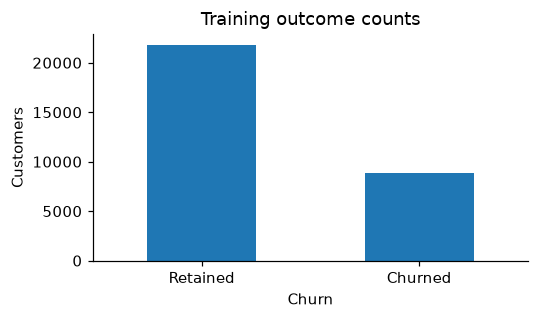

In [2]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
split_summary = pd.DataFrame([
    {"partition": name, "customers": len(labels), "churners": int(labels.sum()),
     "churn_rate": labels.mean()}
    for name, labels in [("all", y), ("training", y_train), ("validation", y_val), ("test", y_test)]
]).set_index("partition")
display(split_summary)
fig, ax = plt.subplots(figsize=(5, 3))
y_train.map({0: "Retained", 1: "Churned"}).value_counts().plot.bar(ax=ax, rot=0)
ax.set(title="Training outcome counts", ylabel="Customers")
plt.tight_layout(); plt.show()

### Missingness and data quality

The audit covers every predictor. Null values and explicit text placeholders are counted separately: a string such as `Unknown` survives the loader as a category. Equal missing-value counts do not prove that fields are missing for the same customers. Duplicate feature rows are checked without displaying individual observations.

The model's existing preprocessing is preserved. It imputes numeric fields with training medians and missingness indicators, standardizes them, and uses most-frequent imputation and one-hot encoding for categorical fields. The notebook does not silently reinterpret placeholder strings, zero ages, or negative charges.

,dtype,missing_n,missing_pct,unique_values,placeholder_n
AgeHH1,float64,544,1.776211,43,0
AgeHH2,float64,544,1.776211,43,0
PercChangeMinutes,float64,209,0.682404,1979,0
PercChangeRevenues,float64,209,0.682404,2494,0
MonthlyRevenue,float64,87,0.284063,10274,0
MonthlyMinutes,float64,87,0.284063,2428,0
TotalRecurringCharge,float64,87,0.284063,202,0
DirectorAssistedCalls,float64,87,0.284063,126,0
OverageMinutes,float64,87,0.284063,639,0
RoamingCalls,float64,87,0.284063,421,0


Duplicate feature rows, training: 0
Duplicate feature rows, entire cohort: 0


,retained_missing_fraction,churned_missing_fraction
MonthlyRevenue,0.001927,0.005098
MonthlyMinutes,0.001927,0.005098
TotalRecurringCharge,0.001927,0.005098
DirectorAssistedCalls,0.001927,0.005098
OverageMinutes,0.001927,0.005098
RoamingCalls,0.001927,0.005098
PercChangeMinutes,0.003945,0.013935
PercChangeRevenues,0.003945,0.013935
ServiceArea,0.000321,0.001020
AgeHH1,0.017890,0.017446


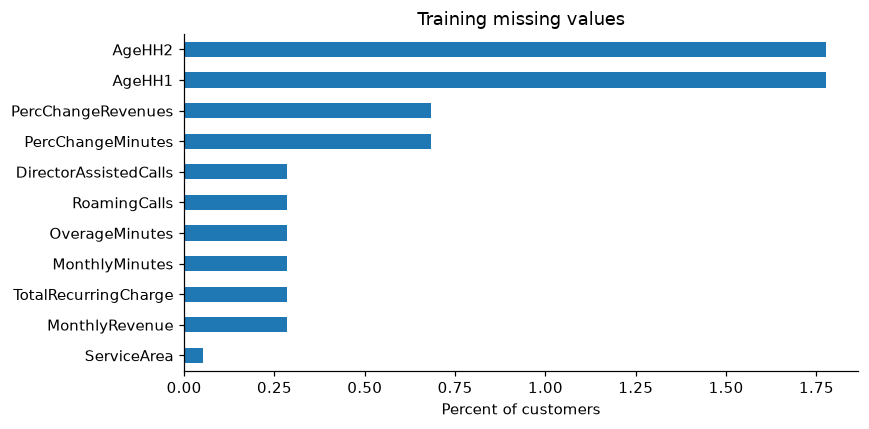

In [3]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()
quality = pd.DataFrame({"dtype": X_train.dtypes.astype(str),
                        "missing_n": X_train.isna().sum(),
                        "missing_pct": X_train.isna().mean().mul(100),
                        "unique_values": X_train.nunique(dropna=True)})
quality["placeholder_n"] = 0
for name in categorical_cols:
    quality.loc[name, "placeholder_n"] = X_train[name].astype("string").str.strip().str.lower().isin(
        ["unknown", "?", "n/a", "na", ""]).sum()
display(quality.sort_values(["missing_pct", "placeholder_n"], ascending=False))
print("Duplicate feature rows, training:", int(X_train.duplicated().sum()))
print("Duplicate feature rows, entire cohort:", int(X.duplicated().sum()))
missing_by_outcome = X_train.isna().groupby(y_train).mean().T
missing_by_outcome.columns = ["retained_missing_fraction", "churned_missing_fraction"]
display(missing_by_outcome.loc[quality.missing_n.gt(0)])
fig, ax = plt.subplots(figsize=(8, 4))
quality.loc[quality.missing_n.gt(0), "missing_pct"].sort_values().plot.barh(ax=ax)
ax.set(title="Training missing values", xlabel="Percent of customers")
plt.tight_layout(); plt.show()

### Data quality findings

The two household age fields each have 544 nulls (1.78% of training customers), the largest null fraction in the audit. Revenue and several usage fields each have 87 nulls. Missing `PercChangeMinutes` is more frequent among churners (1.39%) than retained customers (0.39%), so missingness itself may carry information. This association does not establish the cause of missing records.

Explicit placeholders are much more common than nulls in some fields: `HandsetPrice` contains 17,488 `Unknown` values and `MaritalStatus` contains 11,734. These remain modeled categories. `ServiceArea` has 707 nonnull training categories, making pooled rare categories and unseen test categories relevant even though its null fraction is low. Neither training data nor the full cohort contains duplicate feature rows.

## 2. Numeric features: distributions and churn relationships

The summary includes all numeric predictors, including ordinal codes such as `IncomeGroup`. A numeric dtype does not establish a continuous measurement scale. Histograms are grouped into billing and usage, call quality and service, and account and household characteristics so that tails and zero concentrations remain visible.

Values are plotted on their original scales. Negative billing values and extreme changes require a data dictionary before they can be classified as errors. No trimming, winsorization, or log transformation is applied to model inputs.

,count,mean,std,min,25%,50%,75%,max,zero_fraction,skew
MonthlyRevenue,30540.0,58.647876,43.789112,-2.52,33.58,48.23,70.66,1223.38,0.000065,3.970491
MonthlyMinutes,30540.0,523.405403,526.968661,0.00,158.00,366.00,720.00,7359.00,0.013583,2.192070
TotalRecurringCharge,30540.0,46.771447,23.897718,-11.00,30.00,45.00,60.00,400.00,0.003265,1.788943
DirectorAssistedCalls,30540.0,0.886358,2.271818,0.00,0.00,0.25,0.74,159.39,0.481601,16.873973
OverageMinutes,30540.0,39.807367,92.545637,0.00,0.00,3.00,40.00,2018.00,0.457440,5.789614
RoamingCalls,30540.0,1.168373,8.792012,0.00,0.00,0.00,0.20,1112.40,0.686910,73.043035
PercChangeMinutes,30418.0,-13.366921,259.848407,-3406.00,-84.00,-6.00,64.00,5192.00,0.021582,-0.315418
PercChangeRevenues,30418.0,-1.278957,39.658836,-1107.70,-7.00,-0.30,1.60,2483.50,0.114768,8.580424
DroppedCalls,30627.0,5.983273,8.894213,0.00,0.70,3.00,7.70,221.70,0.150227,4.219592
BlockedCalls,30627.0,4.108238,11.089283,0.00,0.00,1.00,3.70,384.30,0.271786,9.981269


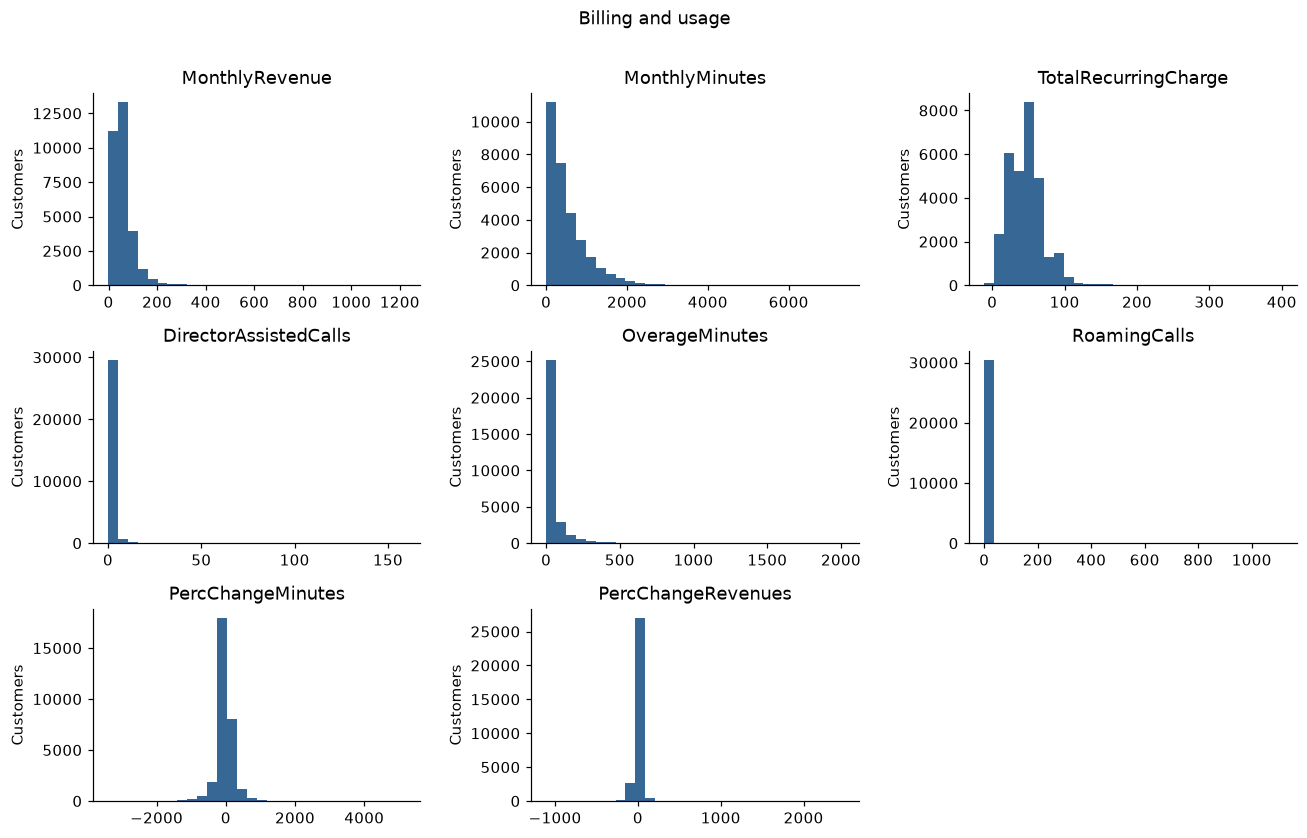

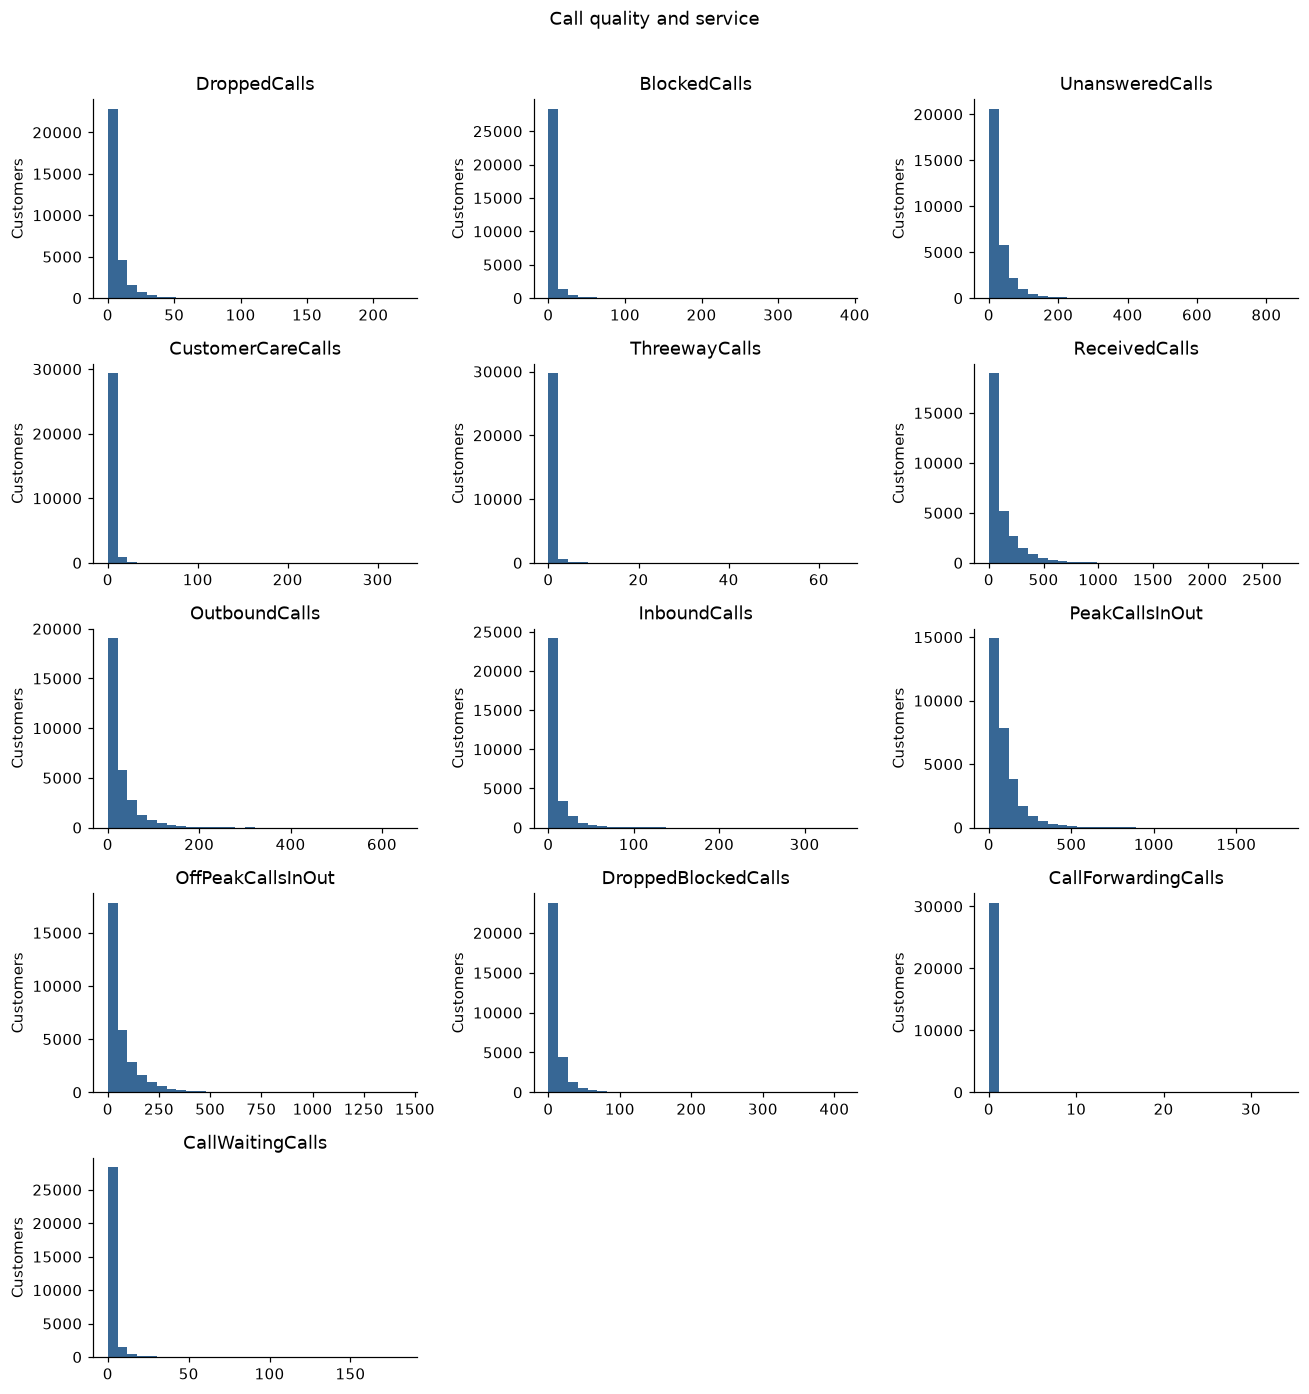

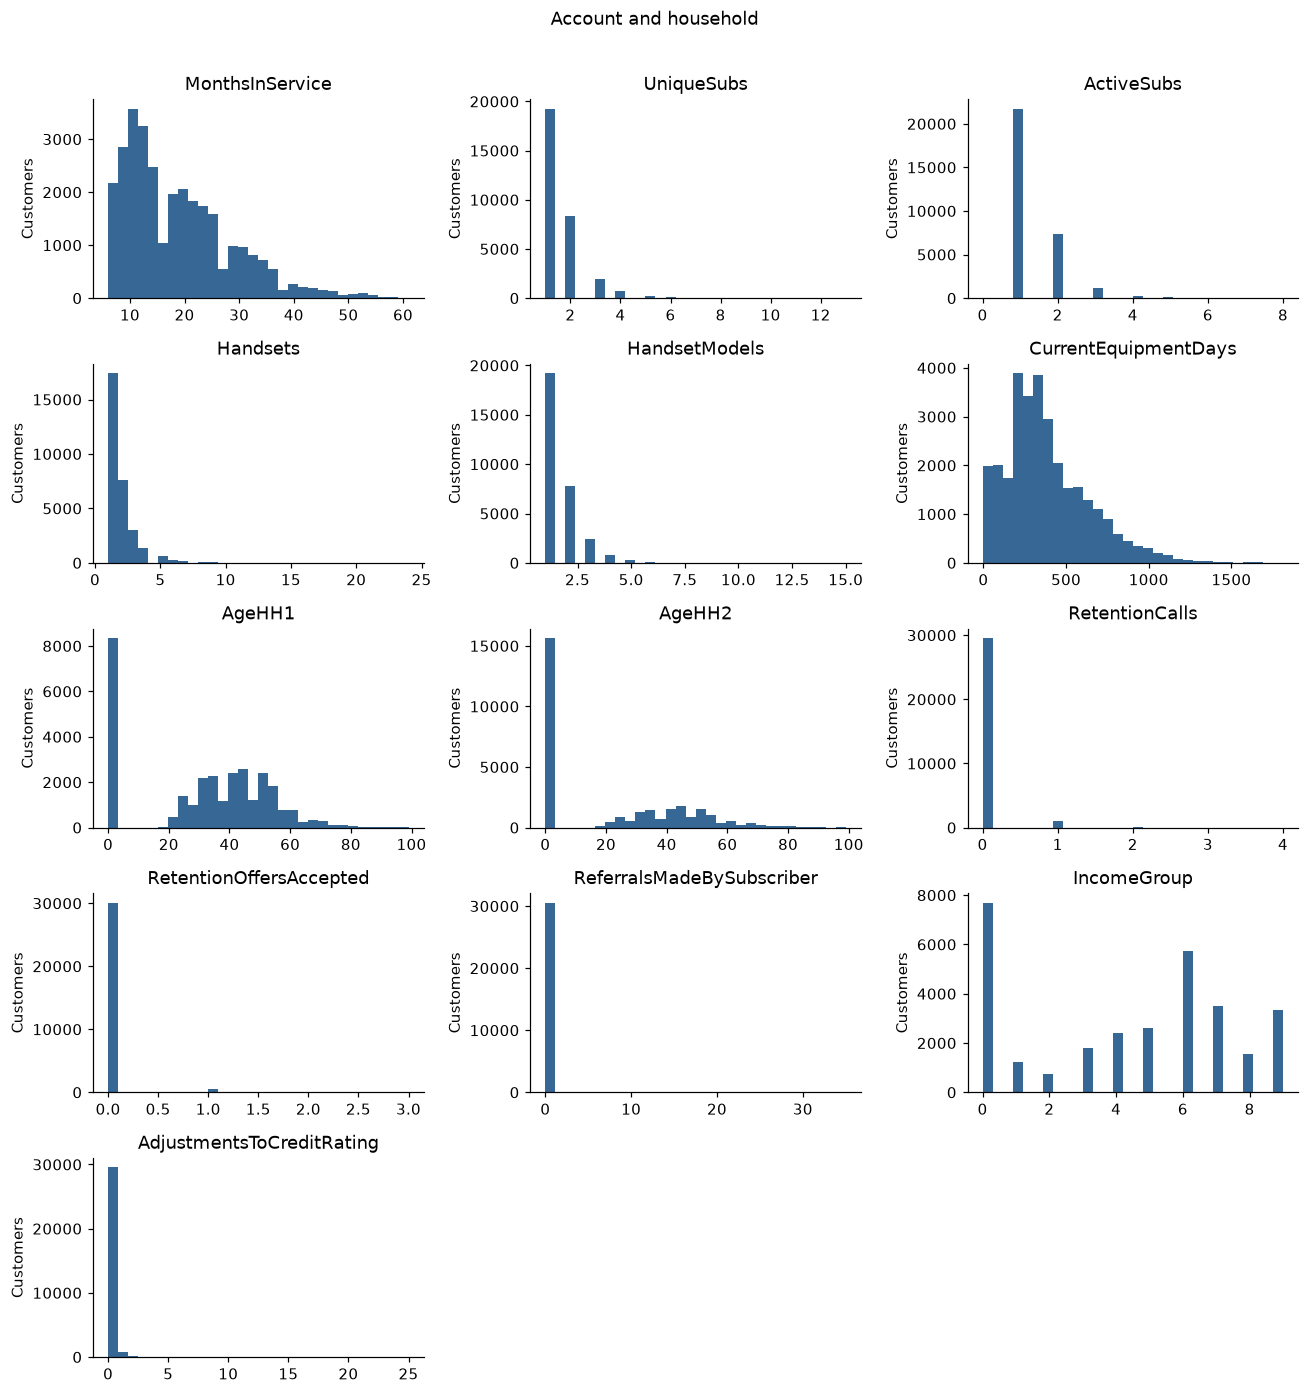

In [4]:
numeric_summary = X_train[numeric_cols].describe().T
numeric_summary["zero_fraction"] = X_train[numeric_cols].eq(0).mean()
numeric_summary["skew"] = X_train[numeric_cols].skew()
display(numeric_summary)
families = {
    "Billing and usage": ["MonthlyRevenue", "MonthlyMinutes", "TotalRecurringCharge", "DirectorAssistedCalls",
                           "OverageMinutes", "RoamingCalls", "PercChangeMinutes", "PercChangeRevenues"],
    "Call quality and service": ["DroppedCalls", "BlockedCalls", "UnansweredCalls", "CustomerCareCalls",
                                 "ThreewayCalls", "ReceivedCalls", "OutboundCalls", "InboundCalls",
                                 "PeakCallsInOut", "OffPeakCallsInOut", "DroppedBlockedCalls",
                                 "CallForwardingCalls", "CallWaitingCalls"]}
covered = {c for group in families.values() for c in group}
families["Account and household"] = [c for c in numeric_cols if c not in covered]
assert set(c for group in families.values() for c in group) == set(numeric_cols)
for family, names in families.items():
    fig, axes = plt.subplots(int(np.ceil(len(names) / 3)), 3, figsize=(12, 2.5 * int(np.ceil(len(names) / 3))))
    for ax, name in zip(np.ravel(axes), names):
        ax.hist(X_train[name].dropna(), bins=30, color="#376795")
        ax.set(title=name, ylabel="Customers")
    for ax in np.ravel(axes)[len(names):]: ax.set_visible(False)
    fig.suptitle(family, y=1.01)
    plt.tight_layout(); plt.show()

### Distribution findings

Training monthly revenue has a mean of 58.65 and median of 48.23; monthly minutes has a mean of 523.41 and median of 366. Both have substantial upper tails. Several call fields concentrate near zero: about 68.7% of training records have zero roaming calls, and about 99.6% have zero call-forwarding calls. Their boxplots can collapse to a line even when a small nonzero tail exists.

Data conventions remain important. Training recurring charge reaches -11.00, equipment age reaches -5 days, and zero appears in 27.3% of `AgeHH1` and 51.1% of `AgeHH2` records. These values should be checked against the original dictionary before interpreting them as literal ages or equipment histories. The frozen model retains them, so its results reflect the existing coding.

### Comparing numeric features by outcome

The class table reports observed counts and medians for every numeric field. The standardized mean difference divides the churned-minus-retained mean by the square root of the average class variance; it provides a descriptive scale comparison. Spearman correlation with churn describes a monotonic relationship. Neither statistic measures a feature's independent contribution to the fitted classifier.

Boxplots cover all numeric fields and hide outlier markers to make the central distributions legible. The preceding summaries and histograms retain the tail information. Training-quantile churn plots for selected operational fields then show whether associations are monotonic or vary across ranges.

,retained_n,churned_n,retained_median,churned_median,standardized_mean_difference,spearman_with_churn
feature,,,,,,
CurrentEquipmentDays,21800,8827,311.000,367.00,0.230096,0.117409
TotalRecurringCharge,21758,8782,45.000,43.00,-0.138516,-0.067462
RetentionCalls,21800,8827,0.000,0.00,0.128063,0.063318
MonthlyMinutes,21758,8782,380.000,327.00,-0.102861,-0.060289
UniqueSubs,21800,8827,1.000,1.00,0.089411,0.043776
PeakCallsInOut,21800,8827,63.000,57.30,-0.080506,-0.046307
CustomerCareCalls,21800,8827,0.000,0.00,-0.080246,-0.053405
PercChangeMinutes,21714,8704,-4.000,-11.00,-0.079763,-0.045757
ReceivedCalls,21800,8827,55.400,45.00,-0.076226,-0.045058


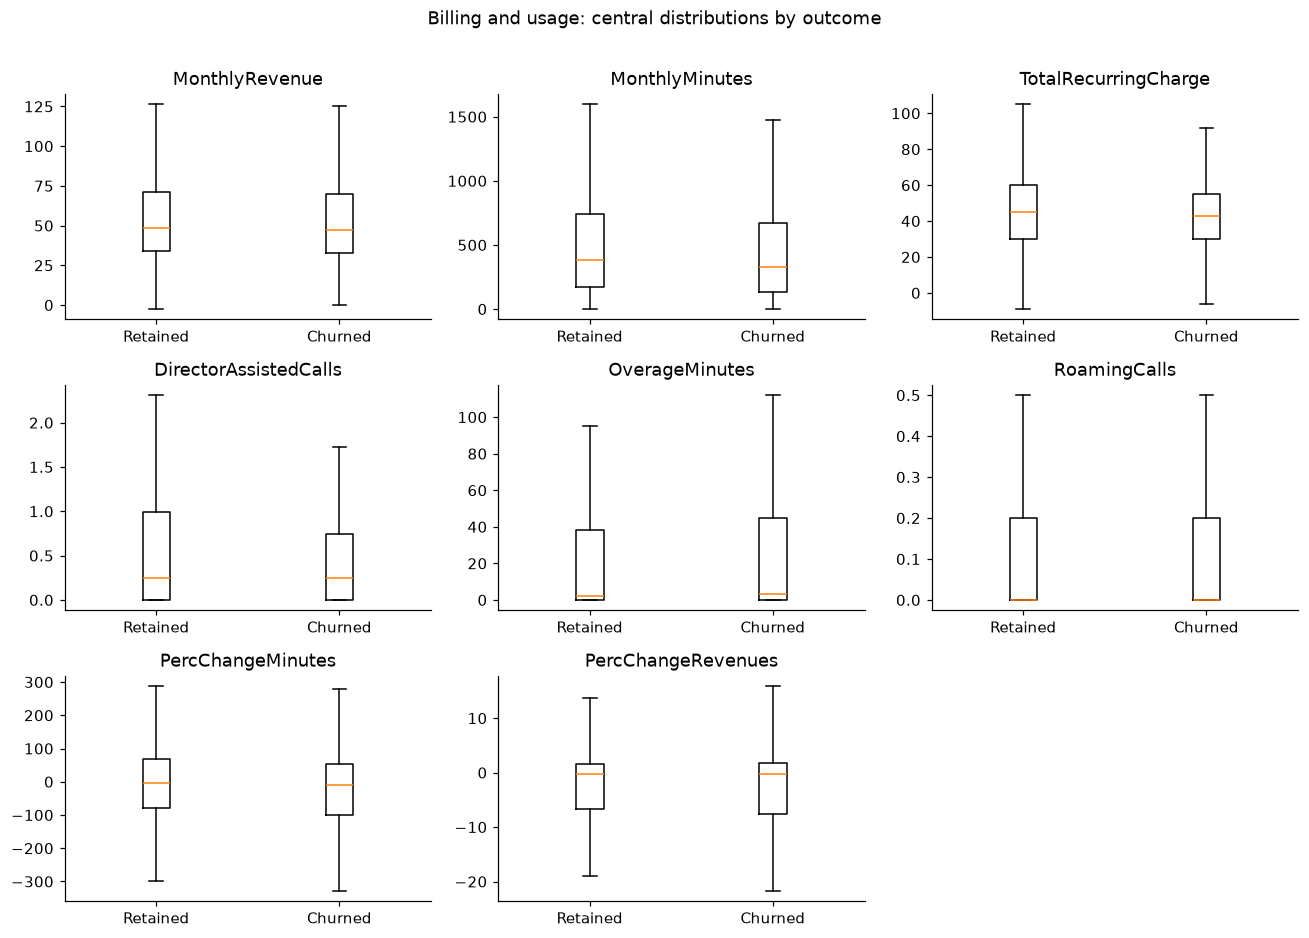

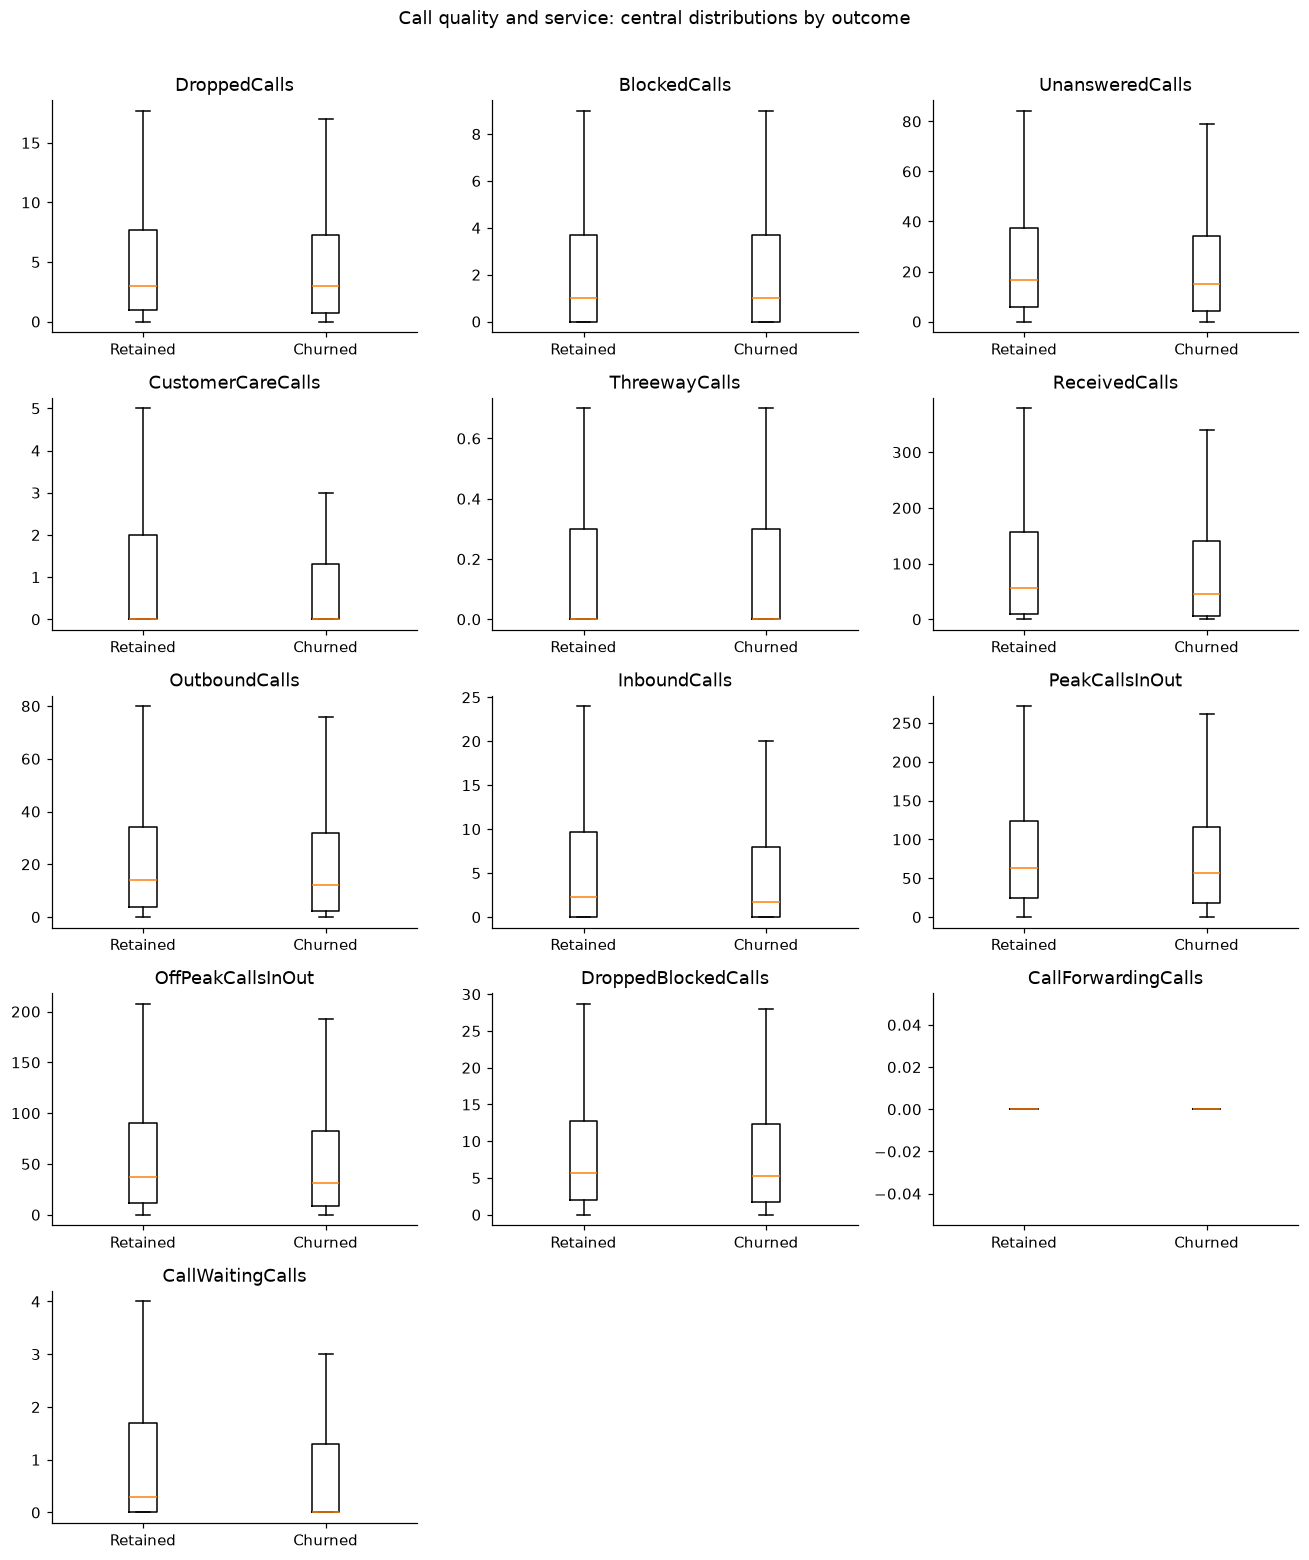

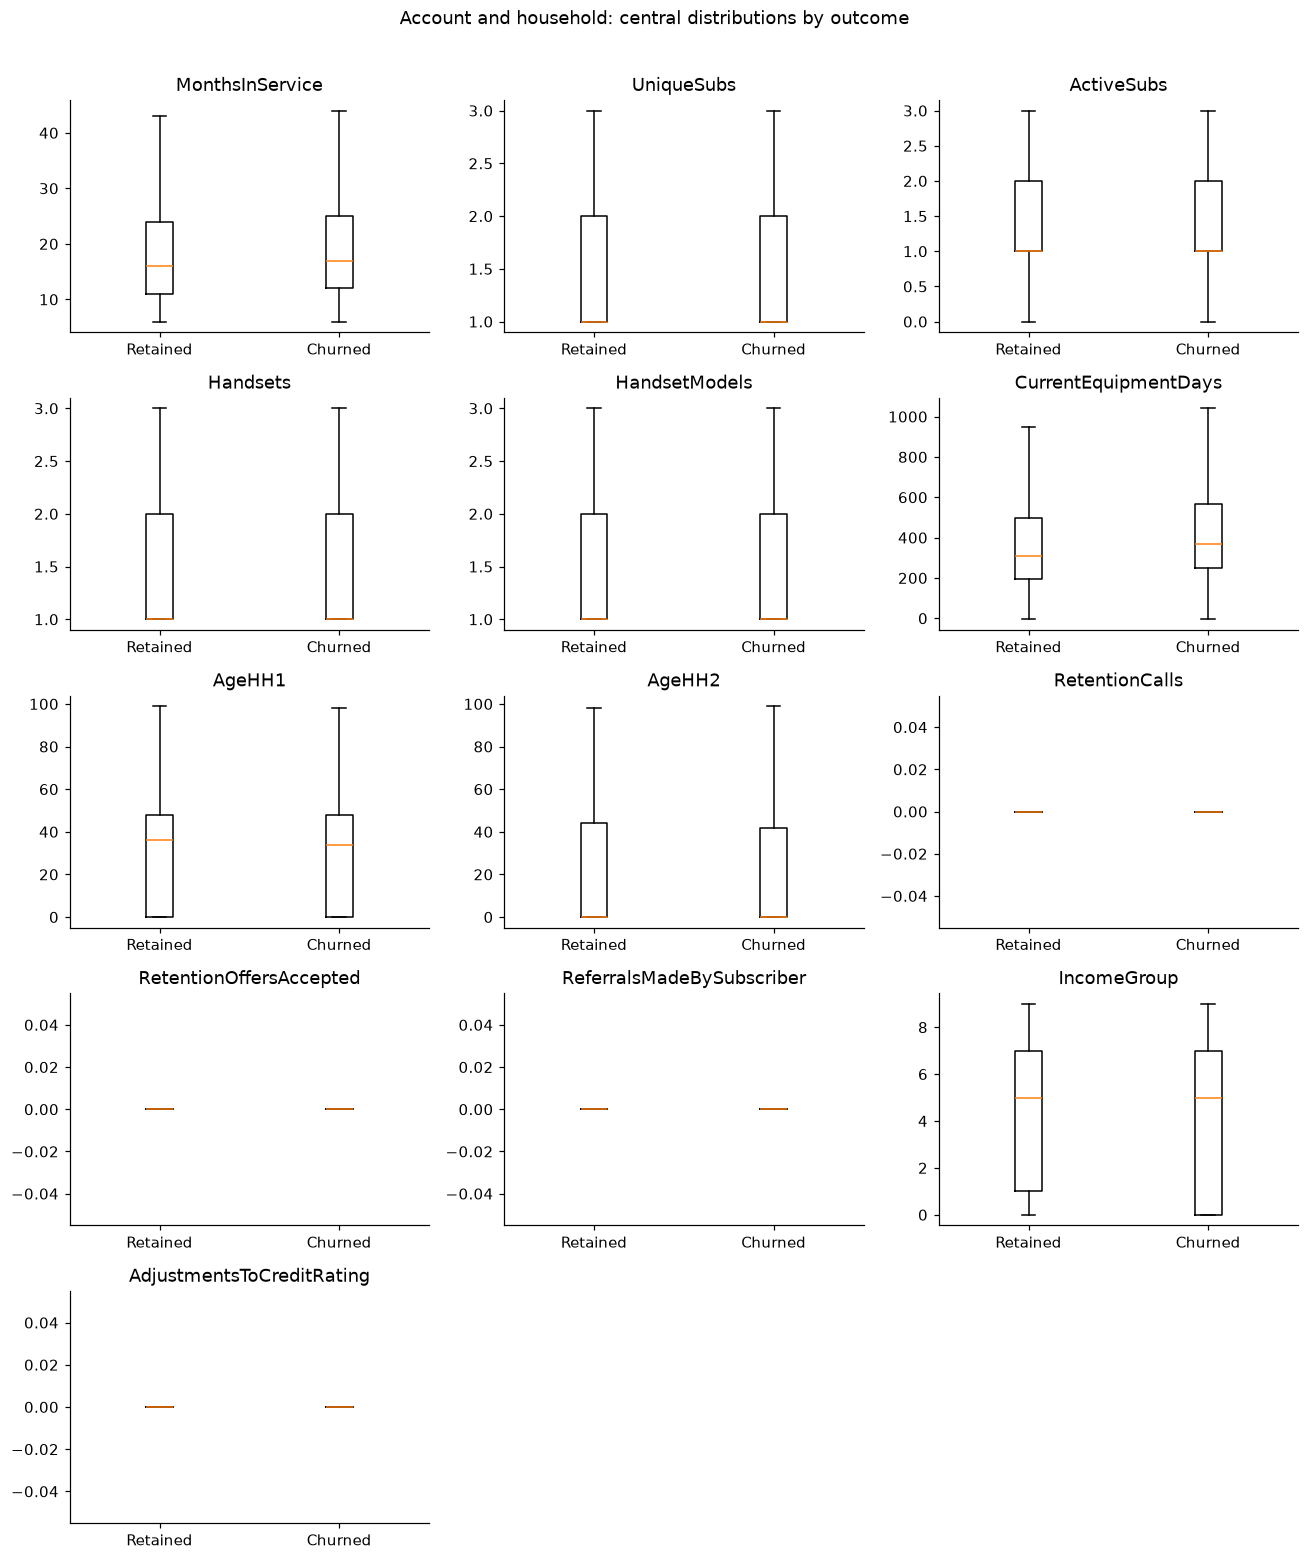

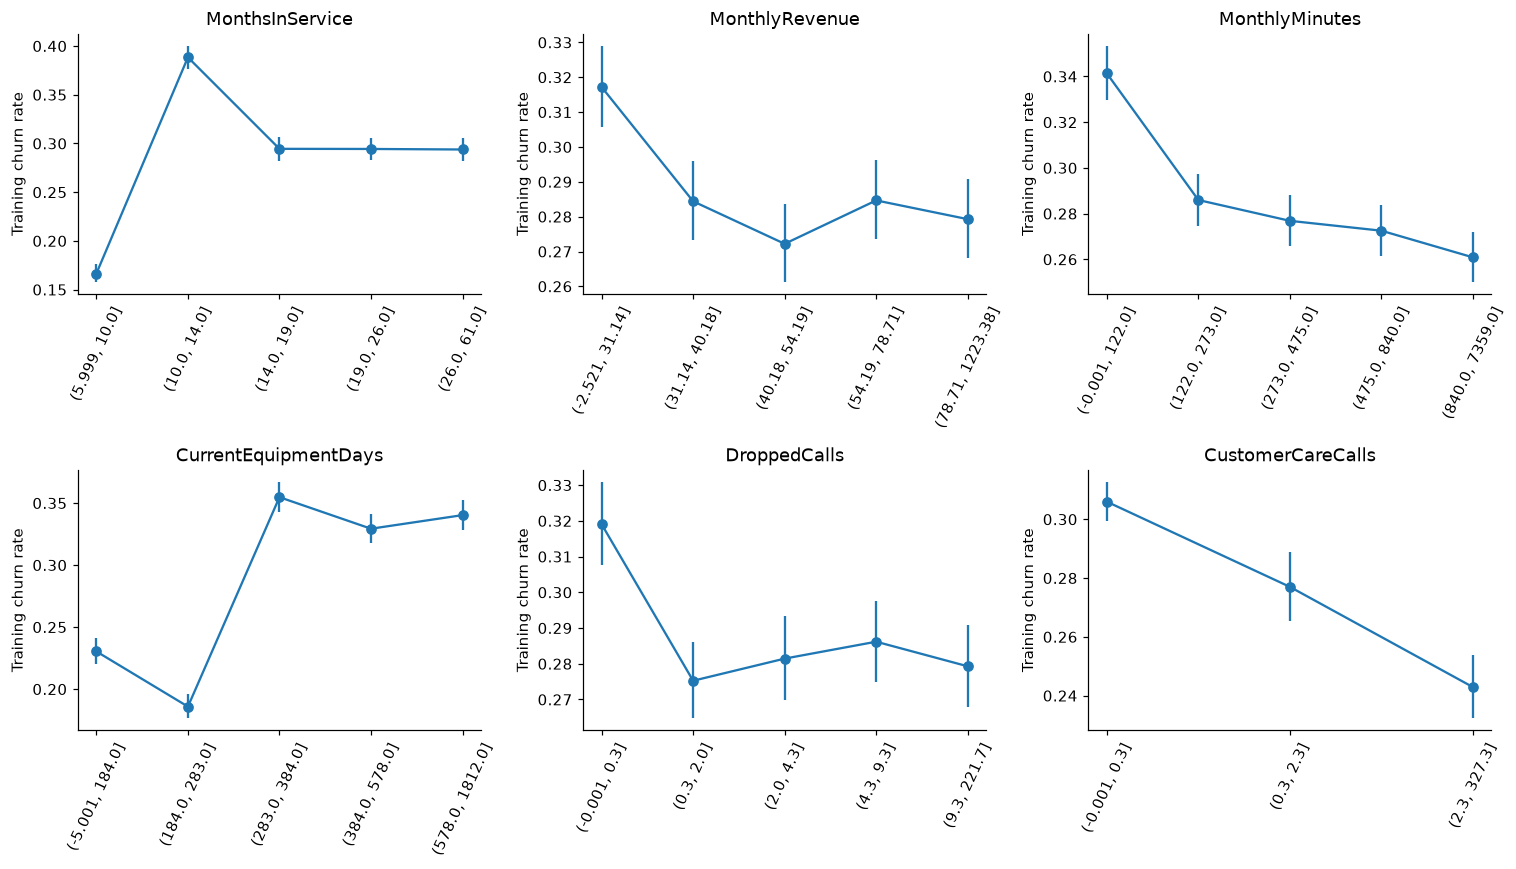

In [5]:
numeric_relations = []
for name in numeric_cols:
    a, b = X_train.loc[y_train.eq(0), name], X_train.loc[y_train.eq(1), name]
    scale = np.sqrt((a.var() + b.var()) / 2)
    numeric_relations.append({"feature": name, "retained_n": a.count(), "churned_n": b.count(),
                              "retained_median": a.median(), "churned_median": b.median(),
                              "standardized_mean_difference": (b.mean() - a.mean()) / scale if scale else np.nan,
                              "spearman_with_churn": X_train[name].corr(y_train, method="spearman")})
numeric_relations = pd.DataFrame(numeric_relations).set_index("feature")
display(numeric_relations.sort_values("standardized_mean_difference", key=abs, ascending=False))
for family, names in families.items():
    fig, axes = plt.subplots(int(np.ceil(len(names) / 3)), 3, figsize=(12, 2.8 * int(np.ceil(len(names) / 3))))
    for ax, name in zip(np.ravel(axes), names):
        ax.boxplot([X_train.loc[y_train.eq(k), name].dropna() for k in [0, 1]], showfliers=False)
        ax.set(title=name, xticks=[1, 2], xticklabels=["Retained", "Churned"])
    for ax in np.ravel(axes)[len(names):]: ax.set_visible(False)
    fig.suptitle(f"{family}: central distributions by outcome", y=1.01)
    plt.tight_layout(); plt.show()

def wilson_interval(successes, totals):
    successes, totals = np.asarray(successes, float), np.asarray(totals, float)
    z = 1.959963984540054
    rate = successes / totals
    denom = 1 + z*z / totals
    center = (rate + z*z/(2*totals)) / denom
    half = z * np.sqrt(rate*(1-rate)/totals + z*z/(4*totals*totals)) / denom
    return center-half, center+half

quantile_fields = ["MonthsInService", "MonthlyRevenue", "MonthlyMinutes", "CurrentEquipmentDays", "DroppedCalls", "CustomerCareCalls"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, name in zip(axes.flat, quantile_fields):
    bins = pd.qcut(X_train[name], q=5, duplicates="drop")
    table = pd.DataFrame({"bin": bins, "churn": y_train}).groupby("bin", observed=True).churn.agg(["sum", "size", "mean"])
    low, high = wilson_interval(table["sum"], table["size"])
    ax.errorbar(np.arange(len(table)), table["mean"], yerr=[table["mean"]-low, high-table["mean"]], fmt="o-")
    ax.set(title=name, ylabel="Training churn rate", xticks=np.arange(len(table)),
           xticklabels=[str(b) for b in table.index])
    ax.tick_params(axis="x", rotation=65)
plt.tight_layout(); plt.show()

### Numeric relationship findings

`CurrentEquipmentDays` has the largest absolute standardized mean difference among the numeric fields examined (0.230). Its median is 367 days among churners and 311 among retained customers. Monthly minutes is lower among churners at the median (327 versus 380). These are group-level tendencies with overlapping distributions, rather than rules that identify individual churners.

The quantile plots also show why a single correlation can miss structure. Tenure's observed churn rate rises sharply after the shortest-tenure bin and then declines, while equipment age has a different pattern. Such shapes motivate comparing a linear classifier with a model that can represent nonlinear splits. They do not establish that the forest's advantage comes from any particular feature.

### Correlations and redundancy

The full numeric Pearson heatmap and the strongest absolute correlation pairs describe linear redundancy. Pairwise-complete observations are used, so missingness can change the sample behind each coefficient. Correlated predictors may share information; dropping one is an experimental choice that has not been tested here. Correlations involving ordinal codes or sparse counts need particular care.

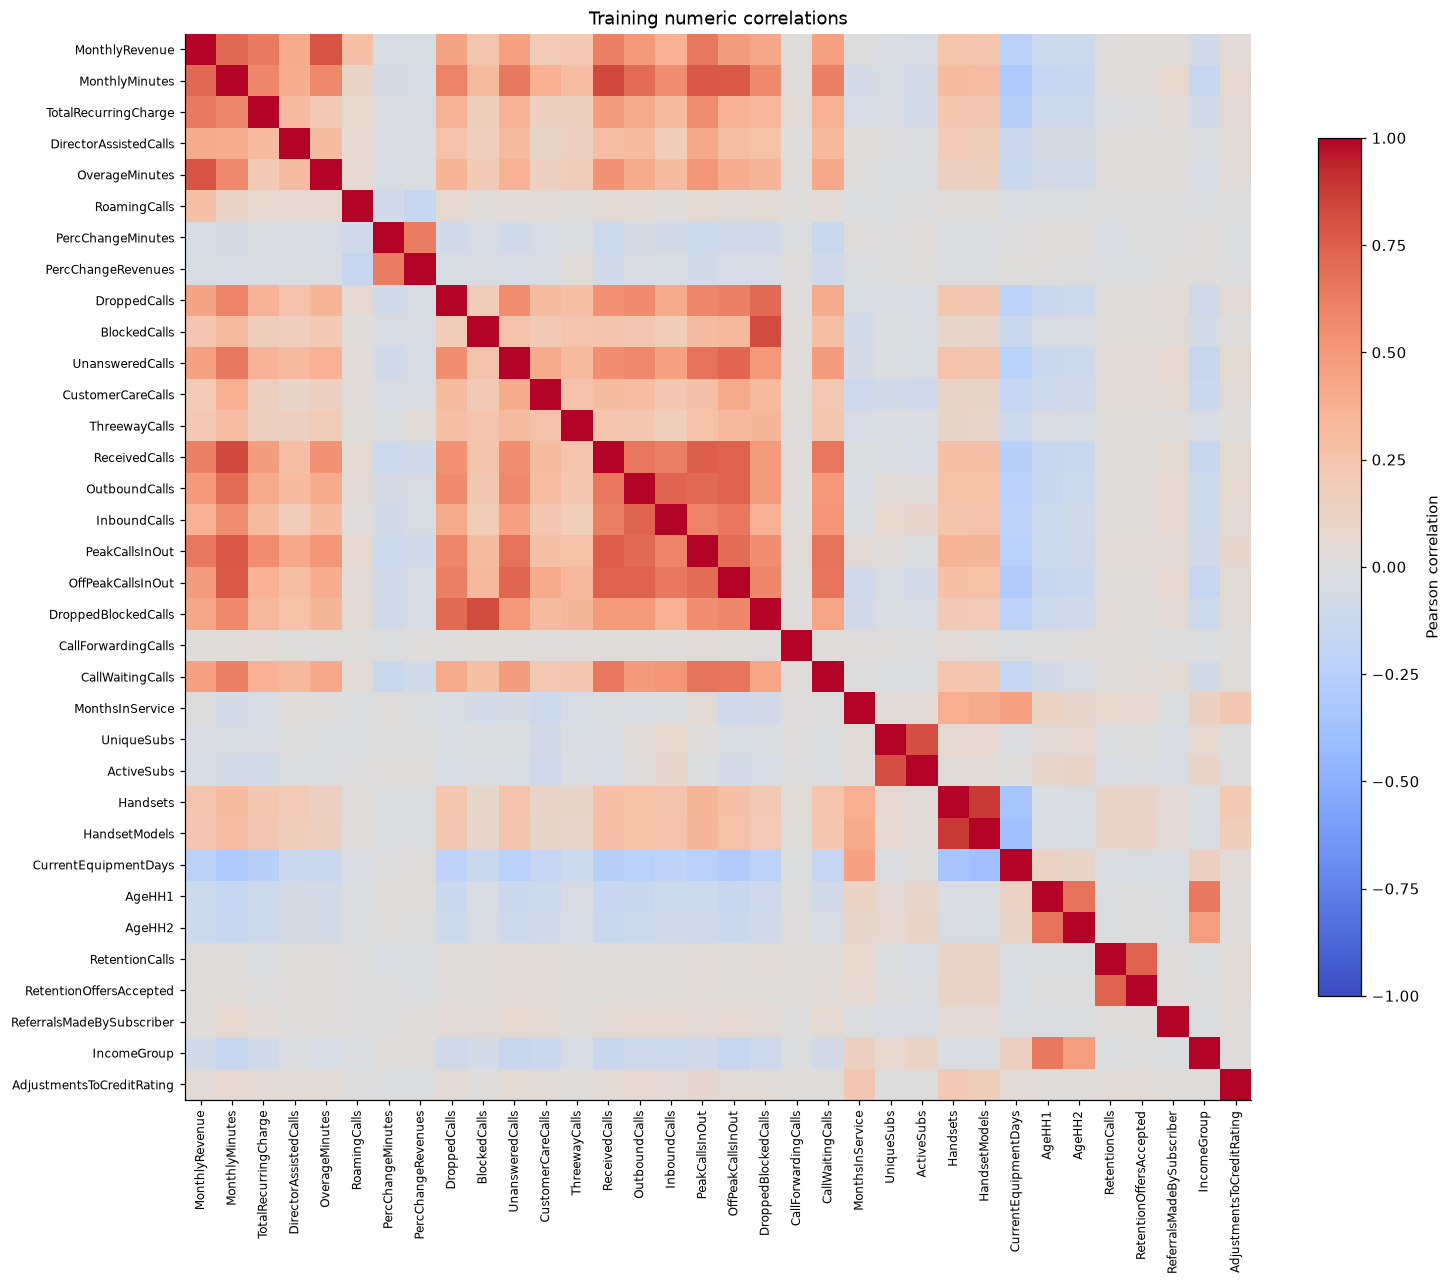

correlation
Handsets        HandsetModels               0.887905
MonthlyMinutes  ReceivedCalls               0.831991
BlockedCalls    DroppedBlockedCalls         0.822306
UniqueSubs      ActiveSubs                  0.805438
MonthlyRevenue  OverageMinutes              0.793879
MonthlyMinutes  PeakCallsInOut              0.775223
                OffPeakCallsInOut           0.769726
ReceivedCalls   PeakCallsInOut              0.751838
OutboundCalls   OffPeakCallsInOut           0.742058
ReceivedCalls   OffPeakCallsInOut           0.739257
RetentionCalls  RetentionOffersAccepted     0.734617
OutboundCalls   InboundCalls                0.726870
UnansweredCalls OffPeakCallsInOut           0.719197
MonthlyRevenue  MonthlyMinutes              0.713658
OutboundCalls   PeakCallsInOut              0.709280
DroppedCalls    DroppedBlockedCalls         0.707618
PeakCallsInOut  OffPeakCallsInOut           0.700117
MonthlyMinutes  OutboundCalls               0.695904
AgeHH1          AgeHH2                      0.676556
UnansweredCalls PeakCallsInOut              0.675067

In [6]:
corr = X_train[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(numeric_cols)), numeric_cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(numeric_cols)), numeric_cols, fontsize=8)
fig.colorbar(im, ax=ax, label="Pearson correlation", shrink=.75)
ax.set_title("Training numeric correlations")
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().rename("correlation")
display(pairs.loc[pairs.abs().sort_values(ascending=False).index].head(20).to_frame())

### Correlation findings

The strongest training pair is `Handsets` with `HandsetModels` (Pearson correlation 0.888). Monthly minutes and received calls correlate at 0.832; blocked calls and the combined dropped/blocked measure correlate at 0.822. These related measurements help explain why a coefficient or marginal relationship cannot be read as an isolated effect. No feature is removed on the strength of the heatmap alone.

## 3. Categorical features and customer segments

Every categorical predictor is included. For each field, the 12 most frequent training categories are retained and the remainder are pooled. Groups below 100 customers are omitted from the displayed aggregate tables and charts. The summary records omitted group and customer counts so that suppression does not look like complete coverage.

Error bars are pointwise 95% Wilson intervals for observed churn frequency. They describe binomial sampling uncertainty under independent observations and are not corrected for the many comparisons. Segment differences may reflect customer mix, historical retention activity, or unmeasured factors. They do not estimate an intervention effect.

,observed_categories,displayed_groups,omitted_groups,omitted_customers
feature,,,,
ServiceArea,708,13,0,0
ChildrenInHH,2,2,0,0
HandsetRefurbished,2,2,0,0
HandsetWebCapable,2,2,0,0
TruckOwner,2,2,0,0
RVOwner,2,2,0,0
Homeownership,2,2,0,0
BuysViaMailOrder,2,2,0,0
RespondsToMailOffers,2,2,0,0


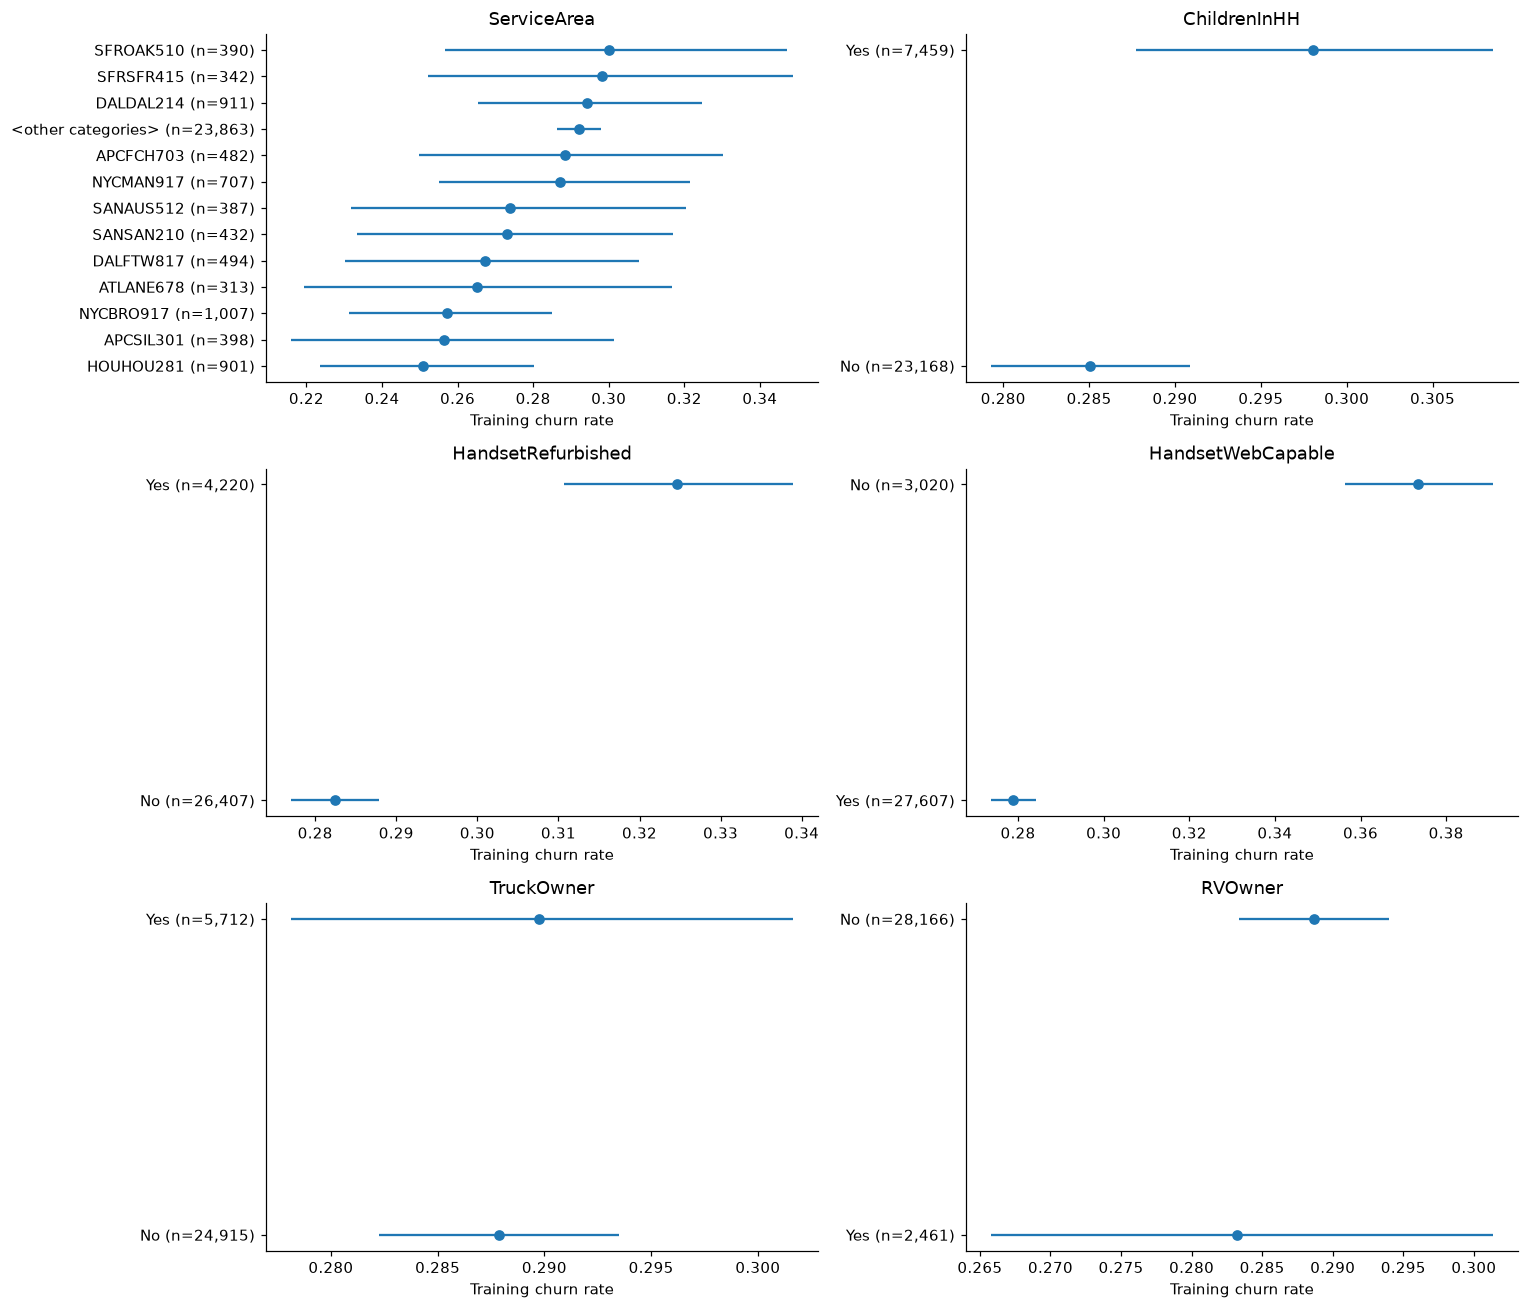

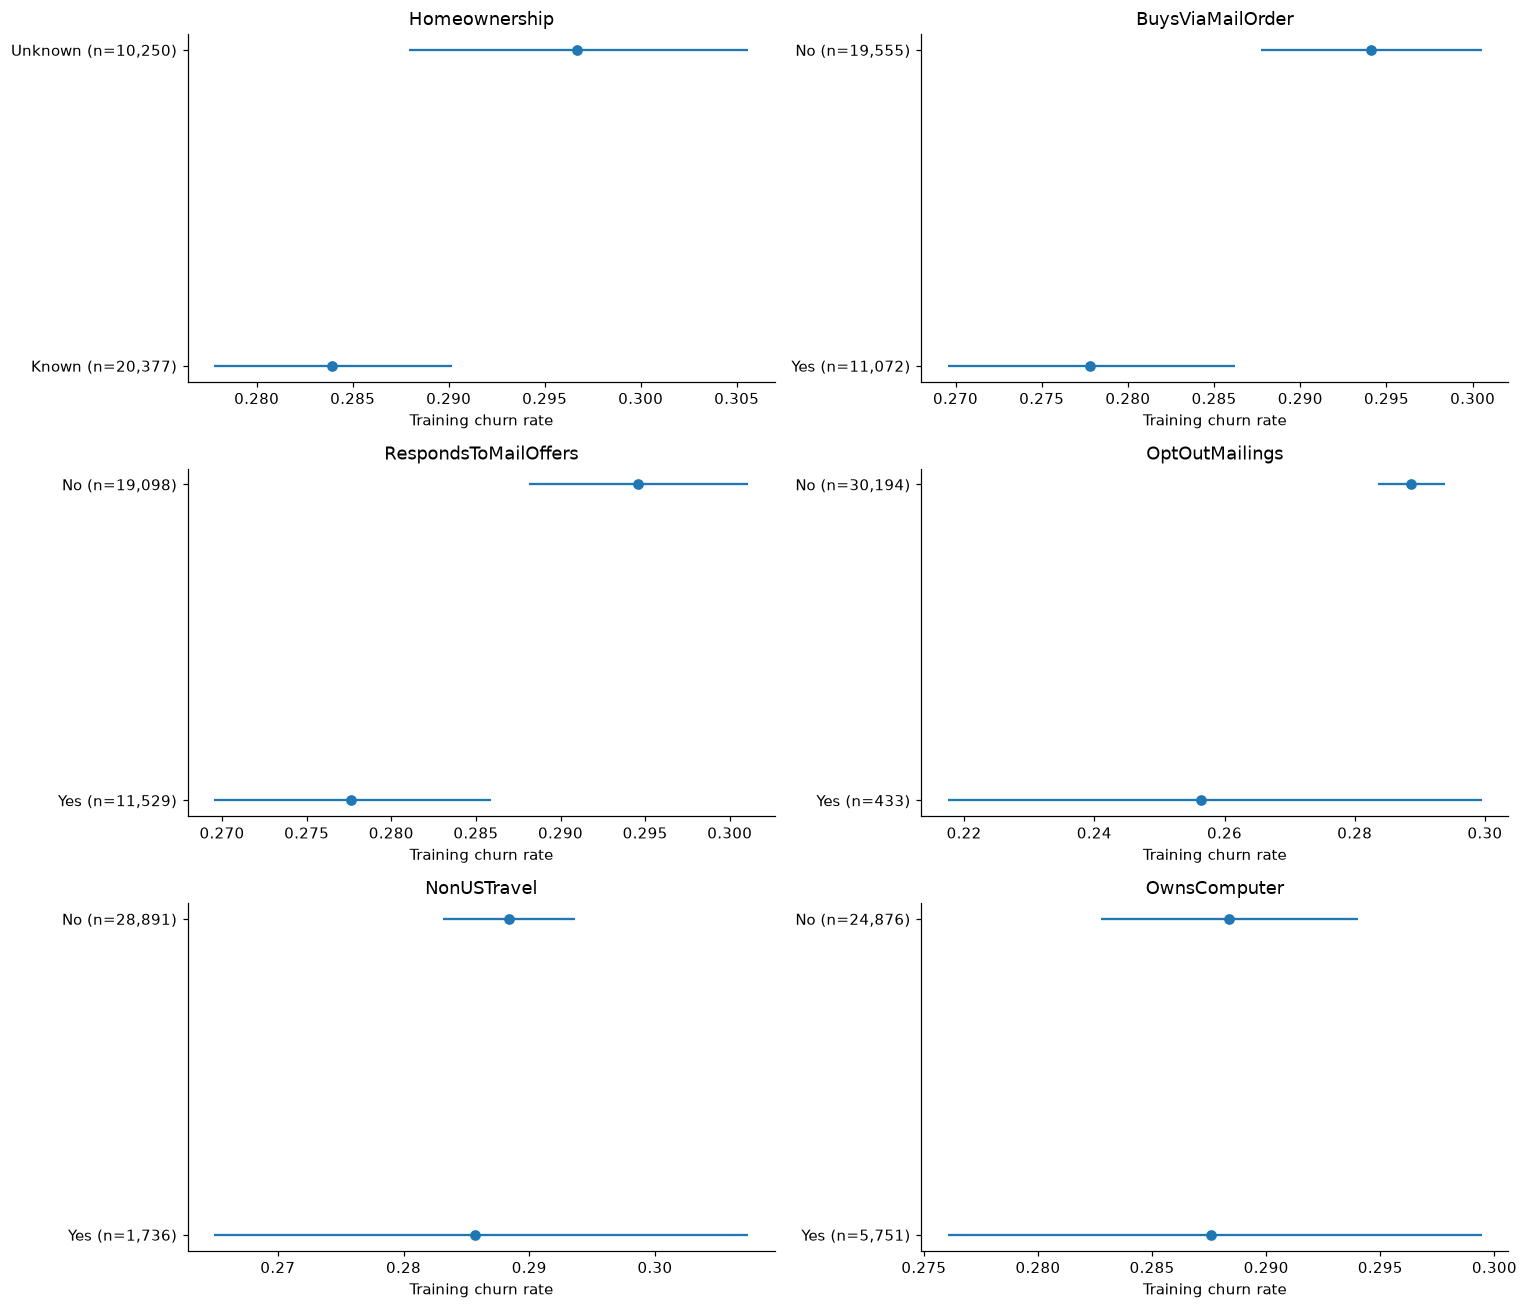

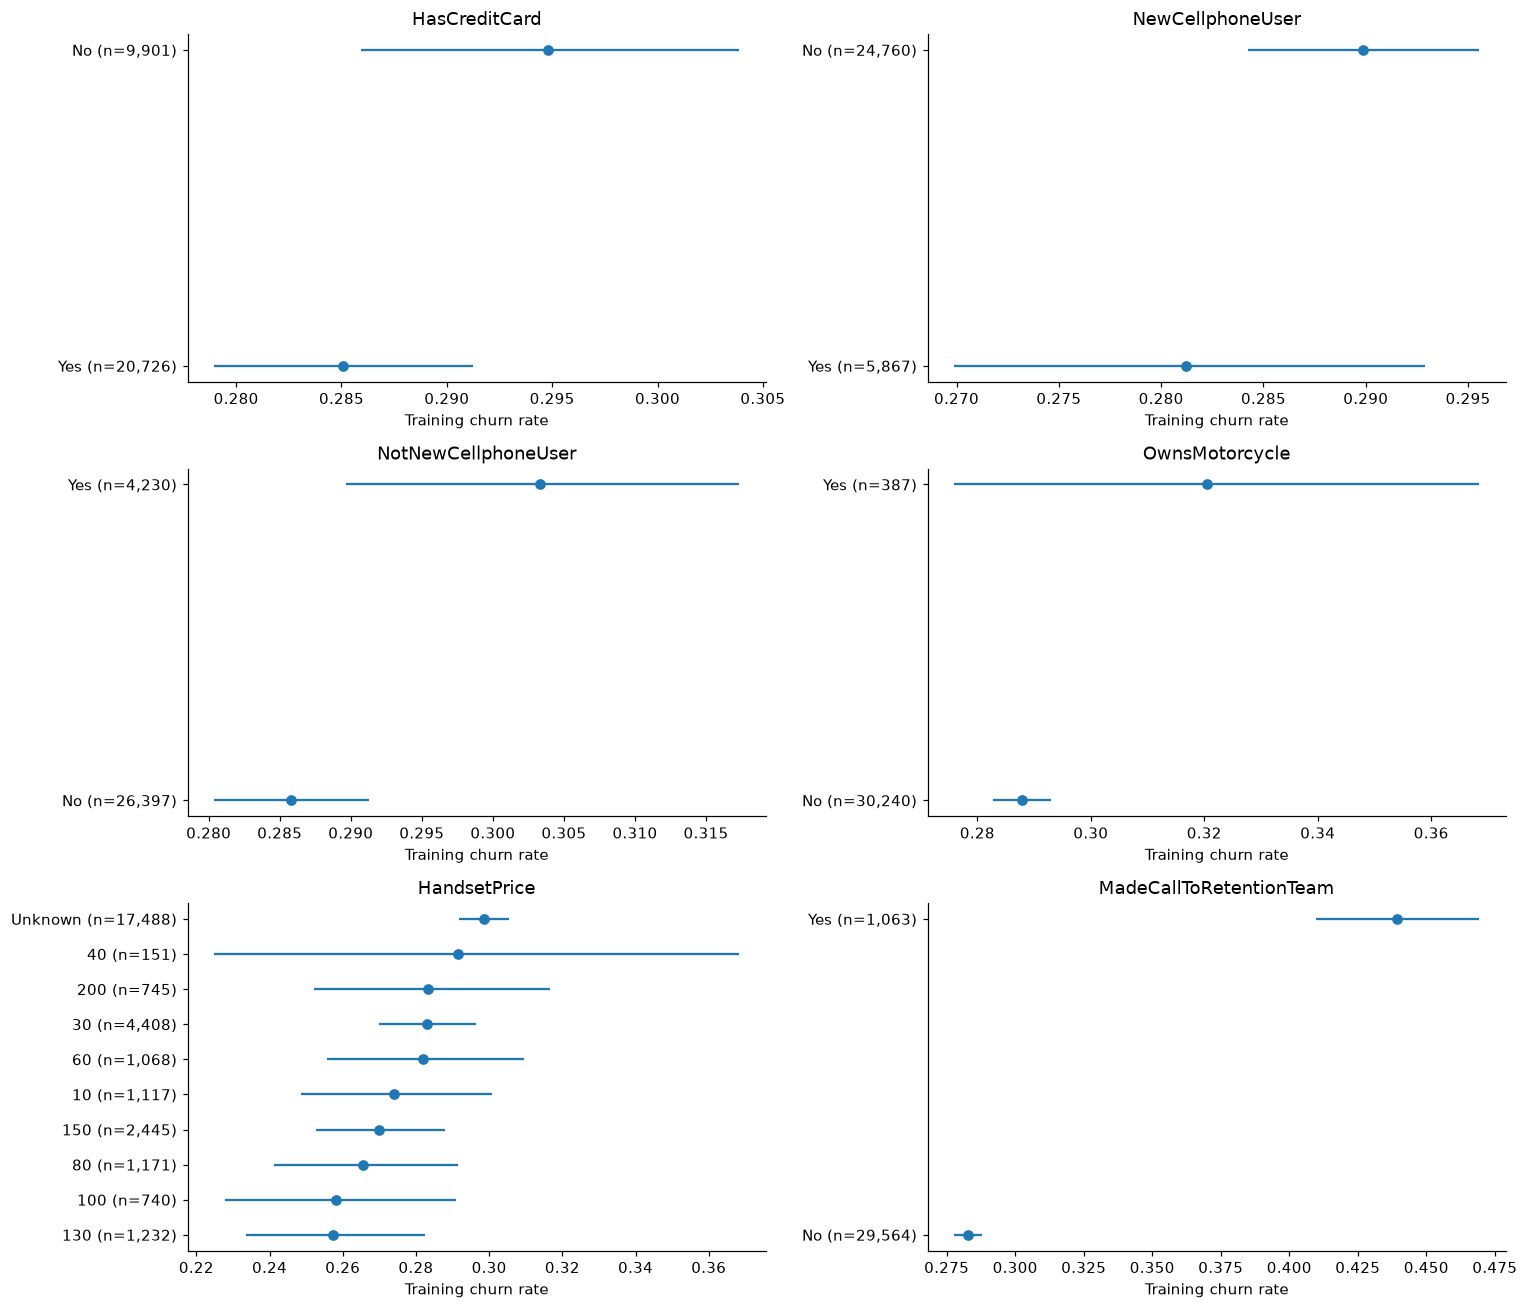

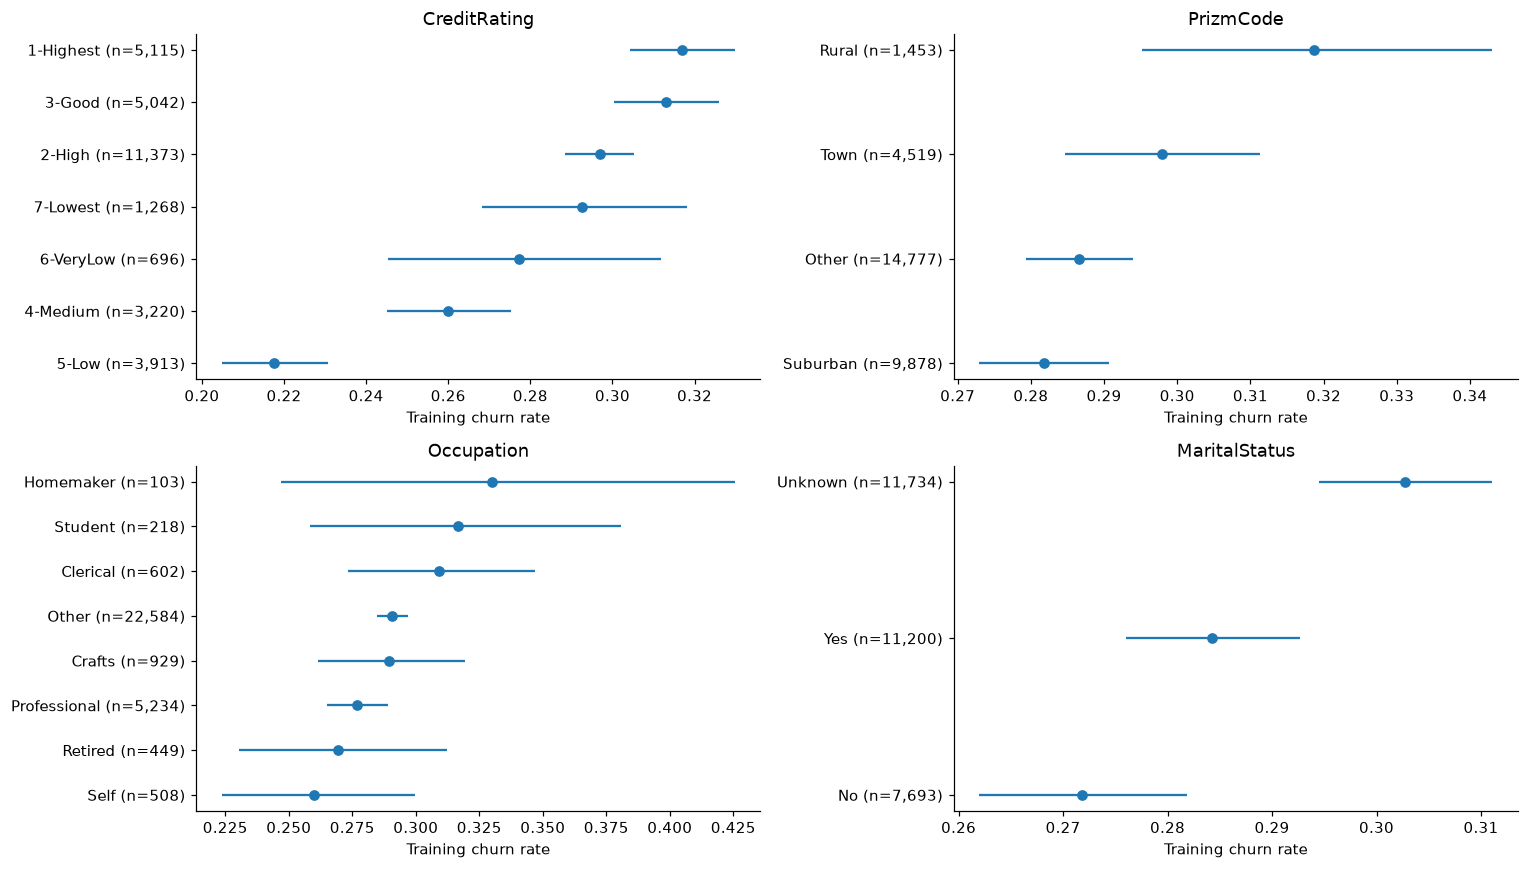

ServiceArea


,churners,customers,churn_rate,low_95,high_95
category,,,,,
HOUHOU281,226,901,0.250832,0.223625,0.280155
APCSIL301,102,398,0.256281,0.215862,0.301361
NYCBRO917,259,1007,0.257200,0.231162,0.285083
ATLANE678,83,313,0.265176,0.219334,0.316712
DALFTW817,132,494,0.267206,0.230091,0.307914
SANSAN210,118,432,0.273148,0.233268,0.317027
SANAUS512,106,387,0.273902,0.231856,0.320392
NYCMAN917,203,707,0.287129,0.255000,0.321558
APCFCH703,139,482,0.288382,0.249738,0.330371


CreditRating


,churners,customers,churn_rate,low_95,high_95
category,,,,,
5-Low,851,3913,0.217480,0.204835,0.230680
4-Medium,837,3220,0.259938,0.245081,0.275367
6-VeryLow,193,696,0.277299,0.245332,0.311710
7-Lowest,371,1268,0.292587,0.268202,0.318224
2-High,3376,11373,0.296843,0.288517,0.305307
3-Good,1578,5042,0.312971,0.300318,0.325909
1-Highest,1621,5115,0.316911,0.304302,0.329795


Occupation


,churners,customers,churn_rate,low_95,high_95
category,,,,,
Self,132,508,0.259843,0.223610,0.299680
Retired,121,449,0.269488,0.230531,0.312356
Professional,1449,5234,0.276844,0.264889,0.289126
Crafts,269,929,0.289559,0.261307,0.319544
Other,6567,22584,0.290781,0.284894,0.296739
Clerical,186,602,0.308970,0.273368,0.346995
Student,69,218,0.316514,0.258403,0.380979
Homemaker,34,103,0.330097,0.246830,0.425582


MadeCallToRetentionTeam


,churners,customers,churn_rate,low_95,high_95
category,,,,,
No,8360,29564,0.282776,0.277671,0.287938
Yes,467,1063,0.439323,0.409759,0.469323


HandsetPrice


,churners,customers,churn_rate,low_95,high_95
category,,,,,
130,317,1232,0.257305,0.233676,0.282444
100,191,740,0.258108,0.227886,0.290829
80,311,1171,0.265585,0.241086,0.291617
150,660,2445,0.269939,0.252713,0.287886
10,306,1117,0.273948,0.248602,0.300844
60,301,1068,0.281835,0.255672,0.309562
30,1247,4408,0.282895,0.269792,0.296376
200,211,745,0.283221,0.252044,0.316623
40,44,151,0.291391,0.224807,0.368325


In [7]:
category_tables = {}
category_coverage = []
for name in categorical_cols:
    values = X_train[name].astype("string").fillna("<missing>")
    common = values.value_counts().head(12).index
    grouped = values.where(values.isin(common), "<other categories>")
    table = pd.DataFrame({"category": grouped, "churn": y_train}).groupby("category").churn.agg(["sum", "size", "mean"])
    omitted = table["size"].lt(100)
    category_coverage.append({"feature": name, "observed_categories": values.nunique(),
                              "displayed_groups": int((~omitted).sum()), "omitted_groups": int(omitted.sum()),
                              "omitted_customers": int(table.loc[omitted, "size"].sum())})
    table = table.loc[~omitted].sort_values("mean")
    table["low_95"], table["high_95"] = wilson_interval(table["sum"], table["size"])
    category_tables[name] = table.rename(columns={"sum": "churners", "size": "customers", "mean": "churn_rate"})
display(pd.DataFrame(category_coverage).set_index("feature"))
for start in range(0, len(categorical_cols), 6):
    batch = categorical_cols[start:start+6]
    fig, axes = plt.subplots(int(np.ceil(len(batch)/2)), 2, figsize=(14, 4*int(np.ceil(len(batch)/2))))
    for ax, name in zip(np.ravel(axes), batch):
        table = category_tables[name]
        ax.errorbar(table.churn_rate, np.arange(len(table)),
                    xerr=[table.churn_rate-table.low_95, table.high_95-table.churn_rate], fmt="o")
        ax.set(title=name, xlabel="Training churn rate", yticks=np.arange(len(table)),
               yticklabels=[f"{k} (n={n:,})" for k,n in zip(table.index, table.customers)])
    for ax in np.ravel(axes)[len(batch):]: ax.set_visible(False)
    plt.tight_layout(); plt.show()
for name in ["ServiceArea", "CreditRating", "Occupation", "MadeCallToRetentionTeam", "HandsetPrice"]:
    print(name)
    display(category_tables[name])

### Segment findings

Among displayed frequent service areas, training churn rates range from 25.08% for `HOUHOU281` to 30.00% for `SFROAK510`; their intervals overlap. The pooled remainder contains 23,863 customers, so the named areas cover only part of the population. This comparison provides little basis for attributing churn to geography itself.

Prior retention contact has a larger observed contrast: churn is 43.93% among 1,063 customers marked `MadeCallToRetentionTeam=Yes`, compared with 28.28% among 29,564 marked `No`. Customers already considering departure may be more likely to contact retention. The association cannot show that contact caused churn or that further contact would prevent it.

Credit-rating groups do not follow a simple ordering: `5-Low` has 21.75% observed training churn, while `1-Highest` has 31.69%. This cautions against importing assumptions about credit risk into churn risk. Occupation estimates for smaller groups have visibly wider intervals. Three small handset-price groups, totaling 62 customers, are omitted from the displayed category estimates.

### Feature interpretation and leakage risk

Billing, usage, service quality, tenure, handset, and household variables describe different aspects of the same account. Differences across these features may support prediction while remaining confounded by account age, service plans, and historical outreach. The numeric relationship table and category intervals are exploratory; they are not feature-importance estimates or causal effects.

`RetentionCalls`, `RetentionOffersAccepted`, and `MadeCallToRetentionTeam` deserve a timing audit. If they are recorded after the intended prediction point, they could disclose information unavailable when a campaign is planned. The source does not provide the timestamped history needed to settle that question. These variables remain in the frozen benchmark to preserve comparability, and the resulting model cannot be called deployment-ready.

## 4. Model comparison on validation data

The maintained experiment compares a constant training-prevalence score (`majority`), class-weighted logistic regression, and a class-weighted random forest. Logistic regression uses `max_iter=1200`; the forest has 150 trees, depth at most 16, and at least six observations per leaf. All candidates use the existing preprocessing.

Validation average precision chooses the model. Each candidate's classification threshold maximizes validation F1 over the fixed grid from 0.05 to 0.95; ties use the first grid value. The selected fitted model is retained without refitting on combined training and validation records. F1 gives no explicit monetary value to a saved customer or cost to a contact.

Training runs in a temporary directory so that the existing metric files and model artifacts remain unchanged. The recomputed selected model, threshold, and metrics are checked against frozen benchmark values embedded as assertions. These reference constants are not reported as new results; all result tables come from this execution. No pre-existing model or metric artifact is required. Any discrepancy stops execution.

Real-data benchmark reproduced within absolute tolerance 1e-8.


,threshold,average_precision,roc_auc,brier_score,precision,recall,f1,balanced_accuracy
random_forest,0.44,0.428300,0.661908,0.219835,0.363993,0.757308,0.491669,0.610836
logistic_regression,0.43,0.378864,0.622040,0.238424,0.336181,0.789259,0.471520,0.579206
majority,0.05,0.288149,0.500000,0.205119,0.288149,1.000000,0.447384,0.500000


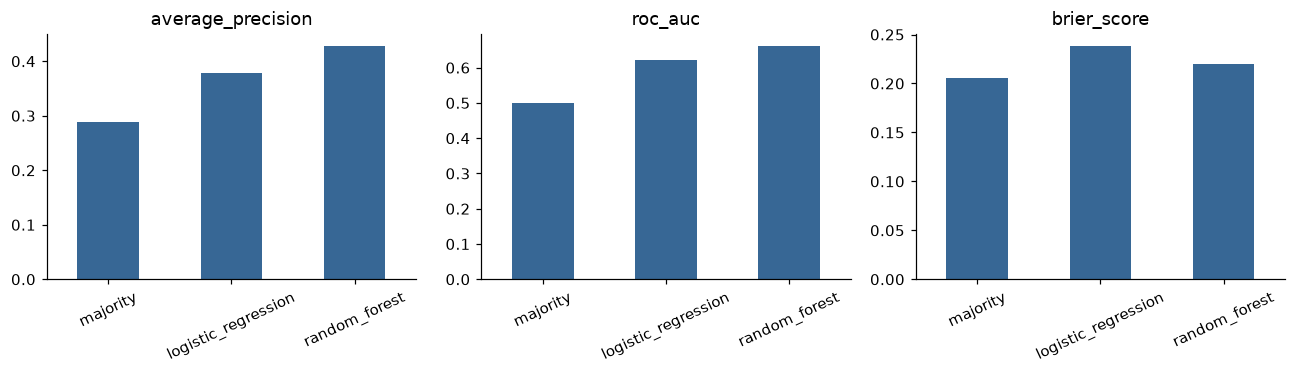

In [8]:
WORK = ROOT / "artifacts/notebook_review"
WORK.mkdir(parents=True, exist_ok=True)
# Frozen values check reproducibility; reported results are recomputed from the CSV.
reference_metrics = {'dataset_sha256': '3f6b8ff0b8e8f5975aa0de9f1f54967e6c8cb867a9bec6cbb64f4c8990f9a645',
 'selected_model': 'random_forest',
 'threshold': 0.43999999999999995,
 'validation': {'majority': {'threshold': 0.05,
                             'average_precision': 0.2881488736532811,
                             'roc_auc': 0.5,
                             'brier_score': 0.2051191039715034,
                             'precision': 0.2881488736532811,
                             'recall': 1.0,
                             'f1': 0.4473844282238443,
                             'balanced_accuracy': 0.5,
                             'confusion_matrix': [[0, 7268], [0, 2942]]},
                'logistic_regression': {'threshold': 0.42999999999999994,
                                        'average_precision': 0.37886378465573345,
                                        'roc_auc': 0.6220396291239885,
                                        'brier_score': 0.23842383453022076,
                                        'precision': 0.3361806862603156,
                                        'recall': 0.7892590074779062,
                                        'f1': 0.47151995126408774,
                                        'balanced_accuracy': 0.579205728284908,
                                        'confusion_matrix': [[2683, 4585], [620, 2322]]},
                'random_forest': {'threshold': 0.43999999999999995,
                                  'average_precision': 0.42830021526525713,
                                  'roc_auc': 0.6619079679153788,
                                  'brier_score': 0.21983452044662172,
                                  'precision': 0.36399281163208624,
                                  'recall': 0.7573079537729436,
                                  'f1': 0.491669425135165,
                                  'balanced_accuracy': 0.6108361452959379,
                                  'confusion_matrix': [[3375, 3893], [714, 2228]]}},
 'test': {'average_precision': 0.42579706976946025,
          'roc_auc': 0.6563350346658027,
          'brier_score': 0.22086031727603,
          'precision': 0.3595121951219512,
          'recall': 0.7515295717199184,
          'f1': 0.4863616366036076,
          'balanced_accuracy': 0.6047823973074,
          'confusion_matrix': [[3329, 3939], [731, 2211]]}}
with tempfile.TemporaryDirectory(prefix="benchmark-", dir=WORK) as output_dir:
    results = run(DATA, Path(output_dir))
    winner_bundle = joblib.load(Path(output_dir) / "model.joblib")
    out = pd.read_csv(Path(output_dir) / "test_predictions.csv")
assert results["dataset_sha256"] == reference_metrics["dataset_sha256"]
assert results["selected_model"] == reference_metrics["selected_model"]
assert np.isclose(results["threshold"], reference_metrics["threshold"], rtol=0, atol=1e-12)
for section in ["test", "validation"]:
    groups = [(results[section], reference_metrics[section])] if section == "test" else [
        (results[section][name], reference_metrics[section][name]) for name in results[section]]
    for actual, expected in groups:
        for metric in actual:
            np.testing.assert_allclose(actual[metric], expected[metric], rtol=0, atol=1e-8)
print("Real-data benchmark reproduced within absolute tolerance 1e-8.")
winner = winner_bundle["pipeline"]
threshold = results["threshold"]
validation = pd.DataFrame(results["validation"]).T.drop(columns="confusion_matrix").astype(float)
display(validation.sort_values("average_precision", ascending=False))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, metric in zip(axes, ["average_precision", "roc_auc", "brier_score"]):
    validation[metric].plot.bar(ax=ax, rot=25, title=metric, color="#376795")
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

### Validation comparison

Random forest leads on validation average precision (0.428300), ahead of logistic regression (0.378864) and the constant baseline (0.288149). At their own F1-selected thresholds, forest precision is 0.363993 with recall 0.757308; logistic regression precision is 0.336181 with recall 0.789259. The forest trades some recall for fewer false alerts per contact at these thresholds.

Probability error reverses part of that comparison: the constant baseline has Brier score 0.205119, better than the forest's 0.219835 and logistic regression's 0.238424. The selected forest is therefore a better ranker than the constant score but a worse probability estimator under squared error in this validation split. The baseline's thresholded predictions flag everyone, explaining its recall of 1.0.

### Ranking at a common outreach capacity

Average precision summarizes ranking over recall levels. ROC-AUC gives a complementary ranking measure, while Brier score measures squared probability error and should be minimized. Class weighting can improve classification behavior while altering probability estimates; probability quality must be assessed separately.

Precision and recall at each candidate's F1 threshold compare different contact volumes. The next table instead compares the top 10%, 20%, and 40% of validation customers under each model. The nonselected baselines are refitted with the unchanged training procedure solely to recover validation scores, and their average precision is verified against the benchmark. No new test-set model selection is performed. Constant-score ties use validation row order; their selected subset has no risk-ranking interpretation.

,model,capacity_fraction,contacts,churners_found,precision,recall,lift_over_prevalence
0,random_forest,0.1,1021,515,0.504407,0.175051,1.750510
1,random_forest,0.2,2042,946,0.463271,0.321550,1.607750
2,random_forest,0.4,4084,1662,0.406954,0.564922,1.412305
3,majority,0.1,1021,303,0.296768,0.102991,1.029912
4,majority,0.2,2042,577,0.282566,0.196125,0.980625
5,majority,0.4,4084,1190,0.291381,0.404487,1.011217
6,logistic_regression,0.1,1021,433,0.424094,0.147179,1.471788
7,logistic_regression,0.2,2042,840,0.411361,0.285520,1.427600
8,logistic_regression,0.4,4084,1541,0.377326,0.523793,1.309483


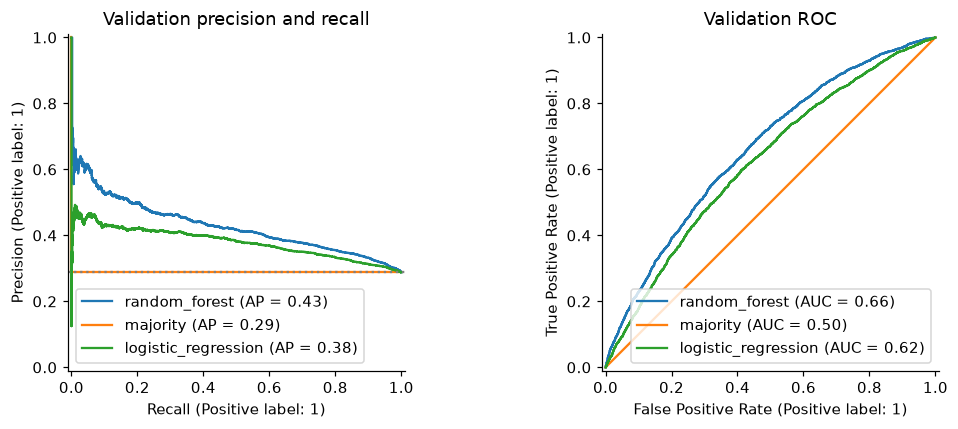

In [9]:
validation_scores = {results["selected_model"]: winner.predict_proba(X_val)[:, 1]}
for name, estimator in [("majority", DummyClassifier(strategy="prior")),
                        ("logistic_regression", LogisticRegression(max_iter=1200, class_weight="balanced", solver="lbfgs"))]:
    model = Pipeline([("preprocess", make_preprocessor()), ("model", estimator)])
    model.fit(X_train, y_train)
    validation_scores[name] = model.predict_proba(X_val)[:, 1]
    np.testing.assert_allclose(average_precision_score(y_val, validation_scores[name]),
                               results["validation"][name]["average_precision"], atol=1e-8, rtol=0)
capacity_rows = []
for name, scores in validation_scores.items():
    ordering = np.argsort(-scores, kind="stable")
    for fraction in [.1, .2, .4]:
        n = int(np.ceil(len(y_val)*fraction))
        captured = int(y_val.to_numpy()[ordering[:n]].sum())
        capacity_rows.append({"model": name, "capacity_fraction": fraction, "contacts": n,
                              "churners_found": captured, "precision": captured/n,
                              "recall": captured/y_val.sum(), "lift_over_prevalence": (captured/n)/y_val.mean()})
capacity_comparison = pd.DataFrame(capacity_rows)
display(capacity_comparison)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for name, scores in validation_scores.items():
    PrecisionRecallDisplay.from_predictions(y_val, scores, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_val, scores, name=name, ax=axes[1])
axes[0].axhline(y_val.mean(), color="grey", ls=":", label="Prevalence")
axes[0].set_title("Validation precision and recall"); axes[1].set_title("Validation ROC")
plt.tight_layout(); plt.show()

### Capacity comparison findings

At a 10% validation contact budget, the forest identifies 515 churners among 1,021 contacts, compared with 433 for logistic regression. Forest precision is 50.44% and recall is 17.51%: concentrating outreach improves precision but leaves most churners outside the campaign. Its precision is 1.75 times validation prevalence.

At 20% capacity, the forest finds 946 churners with precision 46.33% and recall 32.15%; at 40%, it finds 1,662 with precision 40.70% and recall 56.49%. These measured capacity tradeoffs are more useful for planning workload than comparing F1 alone. They remain retrospective validation estimates, and lift over prevalence is not causal retention lift.

## 5. Test performance and bootstrap uncertainty

Test evaluation uses the frozen winner and threshold. The confusion matrix gives false positives (retained customers flagged for outreach) and false negatives (churners missed). Aggregate tables avoid exposing individual customers.

The 95% percentile intervals below use 1,000 ordinary customer-level bootstrap resamples of the test predictions with seed 2026. Both classes must be present in a resample; invalid resamples are skipped and counted. The same resamples support paired comparisons with the constant training-prevalence score. Positive AP and ROC-AUC differences favor the forest; negative Brier differences favor the forest.

These intervals condition on the fitted model, selected threshold, and observed historical cohort. They omit training variability, model-selection uncertainty, dependence between customers, and temporal drift. They are not external-validation intervals. Bootstrap sampling reuses real observations; it does not create synthetic customer records.

,random_forest,constant_probability
average_precision,0.425797,0.288149
roc_auc,0.656335,0.500000
brier_score,0.220860,0.205119
precision,0.359512,NaN
recall,0.751530,NaN
f1,0.486362,NaN
balanced_accuracy,0.604782,NaN


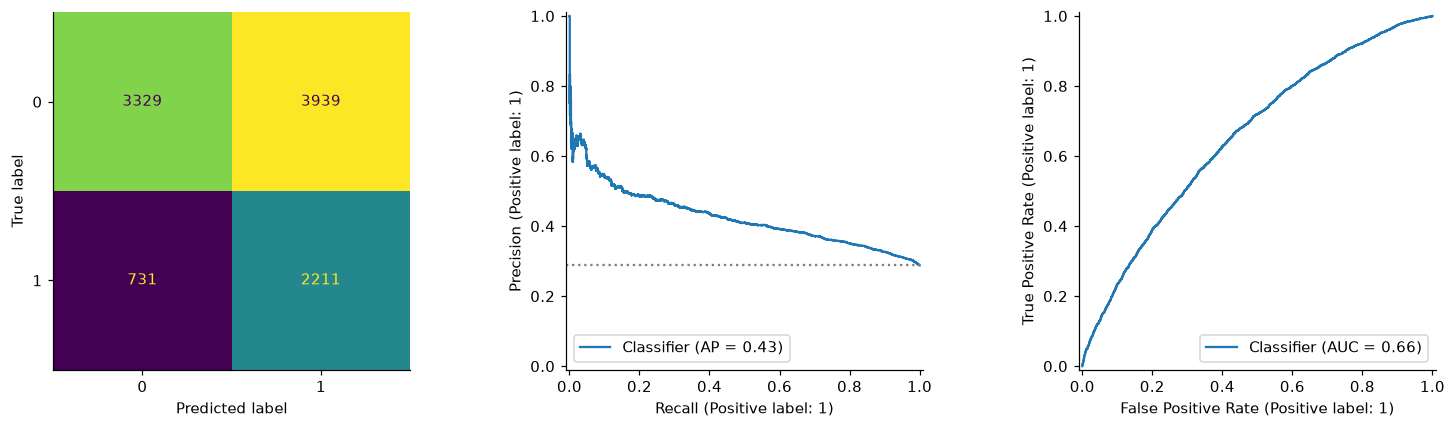

,estimate,low_95,high_95
average_precision,0.425797,0.410342,0.445092
roc_auc,0.656335,0.646235,0.667976
brier_score,0.220860,0.219066,0.222436
precision,0.359512,0.346977,0.371112
recall,0.751530,0.736077,0.767451
f1,0.486362,0.472828,0.499158


,estimate,low_95,high_95
average_precision,0.137648,0.124894,0.153490
brier_score,0.015741,0.012266,0.019440
roc_auc,0.156335,0.146235,0.167976


Valid bootstrap resamples: 1000 of 1000


In [10]:
assert np.array_equal(out.row_index.to_numpy(), X_test.index.to_numpy())
assert np.array_equal(out.actual_churn.to_numpy(), y_test.to_numpy())
truth = out.actual_churn.to_numpy()
scores = out.churn_probability.to_numpy()
pred = out.predicted_churn.to_numpy()
assert np.array_equal(pred, (scores >= threshold).astype(int))
constant_score = float(y_train.mean())
test_table = pd.DataFrame({"random_forest": {k: v for k,v in results["test"].items() if k != "confusion_matrix"},
                           "constant_probability": {
                               "average_precision": average_precision_score(truth, np.full(len(truth), constant_score)),
                               "roc_auc": .5, "brier_score": brier_score_loss(truth, np.full(len(truth), constant_score))}})
display(test_table)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ConfusionMatrixDisplay.from_predictions(truth, pred, ax=axes[0], colorbar=False)
PrecisionRecallDisplay.from_predictions(truth, scores, ax=axes[1])
axes[1].axhline(truth.mean(), color="grey", ls=":")
RocCurveDisplay.from_predictions(truth, scores, ax=axes[2])
plt.tight_layout(); plt.show()

def score_metrics(labels, probabilities, decisions):
    return {"average_precision": average_precision_score(labels, probabilities),
            "roc_auc": roc_auc_score(labels, probabilities),
            "brier_score": brier_score_loss(labels, probabilities),
            "precision": precision_score(labels, decisions, zero_division=0),
            "recall": recall_score(labels, decisions, zero_division=0),
            "f1": f1_score(labels, decisions, zero_division=0)}

rng = np.random.default_rng(2026)
bootstrap_rows, paired_rows = [], []
for _ in range(1000):
    idx = rng.integers(0, len(truth), len(truth))
    labels, probabilities, decisions = truth[idx], scores[idx], pred[idx]
    if len(np.unique(labels)) < 2: continue
    row = score_metrics(labels, probabilities, decisions)
    bootstrap_rows.append(row)
    paired_rows.append({"average_precision": row["average_precision"]-labels.mean(),
                        "roc_auc": row["roc_auc"]-.5,
                        "brier_score": row["brier_score"]-brier_score_loss(labels, np.full(len(labels), constant_score))})
boot = pd.DataFrame(bootstrap_rows)
intervals = pd.DataFrame({"estimate": score_metrics(truth, scores, pred),
                          "low_95": boot.quantile(.025), "high_95": boot.quantile(.975)})
display(intervals)
paired = pd.DataFrame(paired_rows)
paired_intervals = pd.DataFrame({"estimate": test_table.random_forest-test_table.constant_probability,
                                 "low_95": paired.quantile(.025), "high_95": paired.quantile(.975)}).dropna()
display(paired_intervals)
print("Valid bootstrap resamples:", len(boot), "of 1000")

### Test estimates and their uncertainty

Test average precision is 0.425797, with a bootstrap 95% interval of 0.410342 to 0.445092. ROC-AUC is 0.656335 (0.646235 to 0.667976). All 1,000 planned bootstrap resamples contain both classes.

At the frozen threshold, recall is 75.15% (73.61% to 76.75%) and precision is 35.95% (34.70% to 37.11%). The forest identifies 2,211 churners and misses 731, while generating 3,939 false alerts and correctly leaving 3,329 retained customers unflagged.

The paired AP improvement over a constant score is 0.137648, with an interval of 0.124894 to 0.153490. The paired Brier difference is positive at 0.015741 (0.012266 to 0.019440), meaning the forest has greater squared probability error. Within this fixed test cohort, the ranking improvement and probability-quality limitation both persist under resampling.

## 6. Probability calibration

Reliability diagrams compare mean score with observed churn frequency in ten quantile bins. Pointwise Wilson intervals show uncertainty in the observed fraction. Score histograms reveal where most predictions lie; sparse tails should not dominate interpretation.

The validation and test diagnostics use the original model scores. No recalibration is fitted or selected using test labels. Brier score combines several aspects of probability quality, so a worse Brier score than a constant baseline should not be reduced to a single calibration defect. A future recalibration study needs development data for fitting and selection, followed by fresh evaluation.

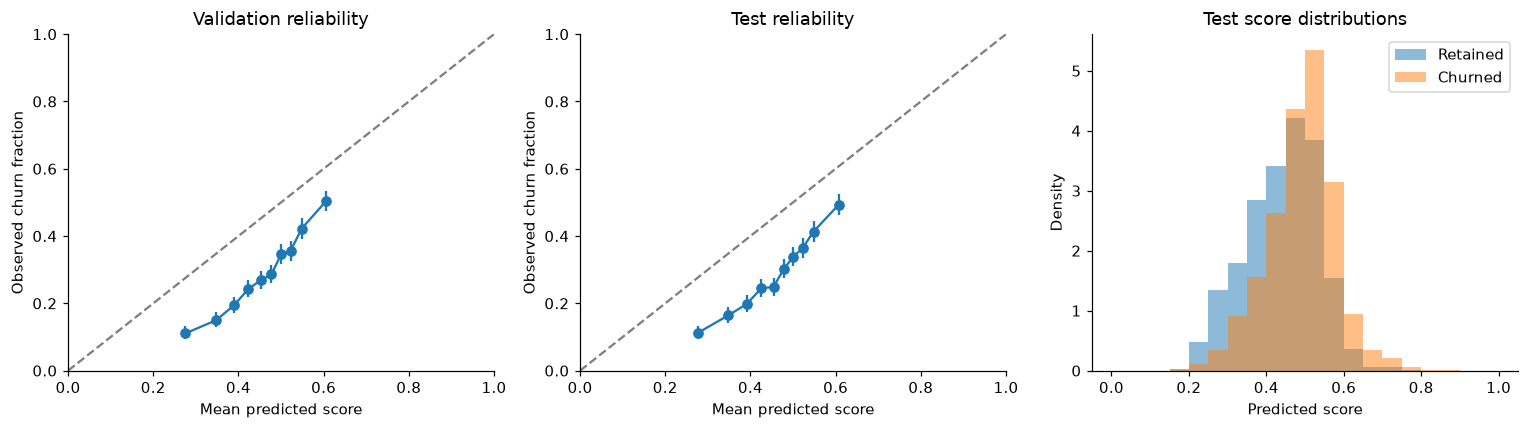

validation


,customers,churners,observed,predicted,low_95,high_95
bin,,,,,,
"(0.181, 0.318]",1021,113,0.110676,0.275234,0.092872,0.131398
"(0.318, 0.371]",1021,153,0.149853,0.347682,0.129274,0.173057
"(0.371, 0.408]",1021,199,0.194907,0.390061,0.171771,0.220330
"(0.408, 0.44]",1021,248,0.242899,0.423473,0.217590,0.270135
"(0.44, 0.466]",1021,275,0.269344,0.453325,0.243035,0.297382
"(0.466, 0.489]",1021,292,0.285994,0.477420,0.259118,0.314474
"(0.489, 0.511]",1021,353,0.345739,0.500074,0.317193,0.375442
"(0.511, 0.533]",1021,363,0.355534,0.522346,0.326764,0.385387
"(0.533, 0.565]",1021,431,0.422135,0.548388,0.392187,0.452667


test


,customers,churners,observed,predicted,low_95,high_95
bin,,,,,,
"(0.17099999999999999, 0.319]",1021,115,0.112635,0.277083,0.094677,0.133497
"(0.319, 0.372]",1021,168,0.164545,0.348276,0.143067,0.188537
"(0.372, 0.409]",1021,202,0.197845,0.390897,0.174562,0.223394
"(0.409, 0.441]",1021,250,0.244858,0.425731,0.219471,0.272158
"(0.441, 0.467]",1021,254,0.248776,0.454135,0.223233,0.276201
"(0.467, 0.49]",1021,309,0.302644,0.478538,0.275248,0.331520
"(0.49, 0.512]",1021,346,0.338883,0.501076,0.310502,0.368473
"(0.512, 0.534]",1021,372,0.364349,0.522625,0.335389,0.394325
"(0.534, 0.564]",1021,422,0.413320,0.548103,0.383495,0.443795


,weighted_bin_absolute_gap,mean_score,observed_prevalence
partition,,,
validation,0.166264,0.454413,0.288149
test,0.167250,0.455399,0.288149


In [11]:
def calibration_table(labels, probabilities):
    frame = pd.DataFrame({"actual": np.asarray(labels), "score": probabilities})
    frame["bin"] = pd.qcut(frame.score, q=10, duplicates="drop")
    table = frame.groupby("bin", observed=True).agg(customers=("actual", "size"), churners=("actual", "sum"),
                                                   observed=("actual", "mean"), predicted=("score", "mean"))
    table["low_95"], table["high_95"] = wilson_interval(table.churners, table.customers)
    return table

calibration = {"validation": calibration_table(y_val, validation_scores["random_forest"]),
               "test": calibration_table(truth, scores)}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, table) in zip(axes[:2], calibration.items()):
    ax.plot([0,1], [0,1], color="grey", ls="--")
    ax.errorbar(table.predicted, table.observed,
                yerr=[table.observed-table.low_95, table.high_95-table.observed], fmt="o-")
    ax.set(title=f"{name.capitalize()} reliability", xlabel="Mean predicted score", ylabel="Observed churn fraction", xlim=(0,1), ylim=(0,1))
for outcome, label in [(0, "Retained"), (1, "Churned")]:
    axes[2].hist(scores[truth==outcome], bins=np.linspace(0,1,21), density=True, alpha=.5, label=label)
axes[2].set(title="Test score distributions", xlabel="Predicted score", ylabel="Density")
axes[2].legend(); plt.tight_layout(); plt.show()
for name, table in calibration.items():
    print(name); display(table)
calibration_summary = pd.DataFrame([
    {"partition": name, "weighted_bin_absolute_gap": np.average(abs(t.observed-t.predicted), weights=t.customers),
     "mean_score": np.average(t.predicted, weights=t.customers), "observed_prevalence": t.churners.sum()/t.customers.sum()}
    for name,t in calibration.items()]).set_index("partition")
display(calibration_summary)

### Calibration findings

Mean forest score is 0.4544 on validation and 0.4554 on test, while observed churn prevalence is 0.2881 in both partitions. Every displayed quantile bin has a mean score above its observed churn fraction. For example, the highest test decile averages 0.6075 predicted risk but has an observed churn fraction of 0.4936.

This consistent overprediction helps explain the Brier comparison and makes the original scores unsuitable for direct expected-value calculations. The ten-bin weighted absolute gap is 0.1672 on test; this is a bin-dependent descriptive statistic, not a universal calibration measure. Similar historical validation and test patterns do not guarantee future calibration.

## 7. Threshold tradeoffs and campaign workload

The final threshold remains the validation-selected value of 0.44. The test sweep is a diagnostic audit, not a search for a replacement threshold. Each row reports contacts, true positives, false positives, false negatives, and the share of the test cohort contacted. Precision and recall cannot be interpreted without this workload.

A true positive is a customer who churned historically and was flagged by the model. It is not a customer whose churn was prevented. Contact may have no effect, and even a retained customer could receive an unnecessary incentive. This dataset does not identify the causal response to a campaign.

,threshold,true_negatives,false_positives,false_negatives,true_positives,contacts,contact_fraction,precision,recall,f1
0,0.10,0,7268,0,2942,10210,1.000000,0.288149,1.000000,0.447384
1,0.15,0,7268,0,2942,10210,1.000000,0.288149,1.000000,0.447384
2,0.20,9,7259,1,2941,10200,0.999021,0.288333,0.999660,0.447573
3,0.25,185,7083,17,2925,10008,0.980215,0.292266,0.994222,0.451737
4,0.30,675,6593,68,2874,9467,0.927228,0.303581,0.976886,0.463212
5,0.35,1328,5940,203,2739,8679,0.850049,0.315589,0.930999,0.471388
6,0.40,2363,4905,433,2509,7414,0.726151,0.338414,0.852821,0.484550
7,0.44,3329,3939,731,2211,6150,0.602351,0.359512,0.751530,0.486362
8,0.45,3604,3664,820,2122,5786,0.566699,0.366747,0.721278,0.486251
9,0.50,5132,2136,1462,1480,3616,0.354163,0.409292,0.503059,0.451357


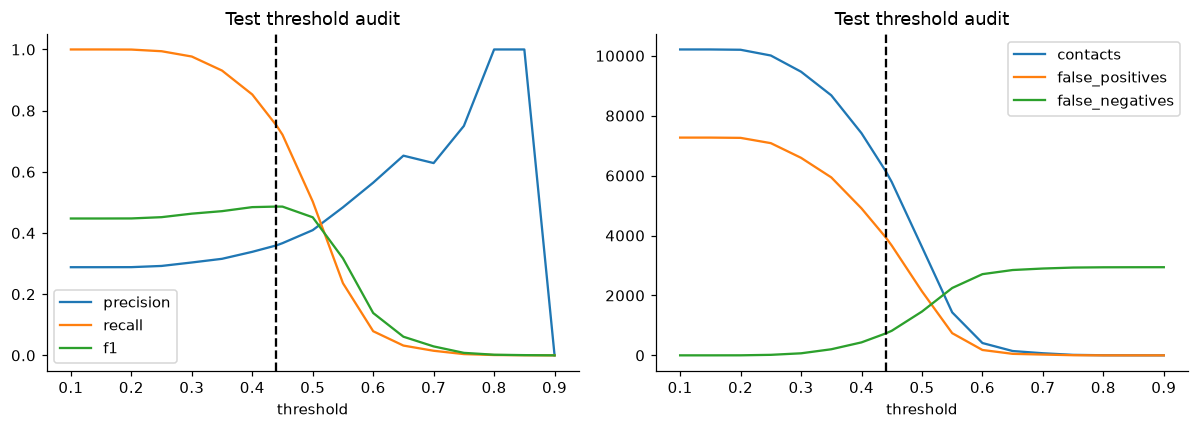

,frozen_threshold
true_negatives,3329.000000
false_positives,3939.000000
false_negatives,731.000000
true_positives,2211.000000
contacts,6150.000000
contact_fraction,0.602351
false_alert_fraction_of_contacts,0.640488
contacts_per_observed_churner_found,2.781547


In [12]:
def decision_counts(labels, decisions):
    tn, fp, fn, tp = confusion_matrix(labels, decisions, labels=[0,1]).ravel()
    return {"true_negatives": int(tn), "false_positives": int(fp), "false_negatives": int(fn), "true_positives": int(tp)}

threshold_rows = []
for t in sorted(set(np.round(np.linspace(.1,.9,17), 2).tolist() + [round(threshold, 2)])):
    decisions = scores >= t
    counts = decision_counts(truth, decisions)
    threshold_rows.append({"threshold": t, **counts, "contacts": int(decisions.sum()),
                           "contact_fraction": decisions.mean(), "precision": precision_score(truth, decisions, zero_division=0),
                           "recall": recall_score(truth, decisions, zero_division=0),
                           "f1": f1_score(truth, decisions, zero_division=0)})
threshold_audit = pd.DataFrame(threshold_rows)
display(threshold_audit)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
threshold_audit.plot(x="threshold", y=["precision", "recall", "f1"], ax=axes[0])
threshold_audit.plot(x="threshold", y=["contacts", "false_positives", "false_negatives"], ax=axes[1])
for ax in axes: ax.axvline(threshold, color="black", ls="--"); ax.set_title("Test threshold audit")
plt.tight_layout(); plt.show()
frozen_counts = decision_counts(truth, pred)
contacts = int(pred.sum())
workload = pd.Series({**frozen_counts, "contacts": contacts, "contact_fraction": pred.mean(),
                      "false_alert_fraction_of_contacts": frozen_counts["false_positives"]/contacts,
                      "contacts_per_observed_churner_found": contacts/frozen_counts["true_positives"]})
display(workload.rename("frozen_threshold").to_frame())

### Business interpretation without assumed profit

For a campaign with contact cost `c`, incremental retained-customer value `v`, and an unknown probability `u` that outreach prevents churn among flagged customers who otherwise would leave, a simplified expected net value is:

`flagged otherwise-churners * u * v - contacts * c`.

This omits incentive costs, adverse reactions, capacity constraints, and the uncertainty about who would churn without contact. The retrospective true-positive count can describe historical exposure, but it cannot identify the counterfactual count or `u`. Consequently no profit estimate is reported. Under the simplifying assumptions, break-even requires `u * v / c > contacts / flagged otherwise-churners`; the observed contacts-per-churner ratio is only a retrospective workload reference.

A campaign study would define a prediction date and churn horizon, estimate incremental treatment effects with an appropriate randomized design, and include intervention costs and realized customer value. A threshold based on those measurements would then need new validation.

## 8. Subgroup errors and missed churners

Subgroups are fixed from training data before the test diagnostic: tenure and revenue use training quartile boundaries; missing revenue is retained as a separate group; credit rating, homeownership, and prior retention contact use training categories with at least 300 customers, pooling the rest. Only test groups with at least 100 customers and at least 20 observations in each outcome class are displayed. Omitted coverage is reported.

False-positive rate divides false alerts by actual retained customers. False-negative rate divides missed churners by actual churners. Precision uses flagged customers as its denominator. These denominators answer different questions and should not be compared as though they were interchangeable.

Each displayed group's 95% percentile intervals use 500 ordinary within-group customer bootstrap resamples, with the fitted model and threshold fixed. Groups overlap across fields, intervals are pointwise, and no multiple-comparison correction is applied. These are descriptive diagnostics, not a fairness certification or evidence that a protected attribute causes an error.

,omitted_groups,omitted_customers
feature,,
MonthsInService,0,0
MonthlyRevenue,1,36
CreditRating,0,0
Homeownership,0,0
MadeCallToRetentionTeam,0,0


,feature,group,customers,actual_churners,actual_retained,flagged,false_positives,false_negatives,false_positive_rate,false_negative_rate,precision
0,MonthsInService,"(-inf, 11.0]",2852,697,2155,804,457,350,0.212065,0.502152,0.431592
1,MonthsInService,"(11.0, 16.0]",2335,816,1519,1840,1142,118,0.751810,0.144608,0.379348
2,MonthsInService,"(16.0, 24.0]",2531,756,1775,1834,1215,137,0.684507,0.181217,0.337514
3,MonthsInService,"(24.0, inf]",2492,673,1819,1672,1125,126,0.618472,0.187221,0.327153
4,MonthlyRevenue,"(-inf, 33.58]",2600,791,1809,1981,1299,109,0.718076,0.137800,0.344271
5,MonthlyRevenue,"(33.58, 48.23]",2465,693,1772,1460,926,159,0.522573,0.229437,0.365753
6,MonthlyRevenue,"(48.23, 70.66]",2533,738,1795,1436,887,189,0.494150,0.256098,0.382312
7,MonthlyRevenue,"(70.66, inf]",2576,705,1871,1239,808,274,0.431855,0.388652,0.347861
8,CreditRating,1-Highest,1698,511,1187,1218,792,85,0.667228,0.166341,0.349754
9,CreditRating,2-High,3807,1169,2638,2492,1565,242,0.593252,0.207015,0.371990


,feature,group,false_positive_rate_low,false_positive_rate_high,false_positive_rate_valid_resamples,false_negative_rate_low,false_negative_rate_high,false_negative_rate_valid_resamples,precision_low,precision_high,precision_valid_resamples
0,MonthsInService,"(-inf, 11.0]",0.195738,0.229512,500,0.462279,0.541576,500,0.397608,0.469637,500
1,MonthsInService,"(11.0, 16.0]",0.729706,0.772788,500,0.121454,0.170423,500,0.358131,0.401708,500
2,MonthsInService,"(16.0, 24.0]",0.662904,0.704952,500,0.154455,0.207976,500,0.313002,0.360312,500
3,MonthsInService,"(24.0, inf]",0.596618,0.642393,500,0.158274,0.213494,500,0.304863,0.350252,500
4,MonthlyRevenue,"(-inf, 33.58]",0.698192,0.739419,500,0.114371,0.163189,500,0.324518,0.364403,500
5,MonthlyRevenue,"(33.58, 48.23]",0.500691,0.545789,500,0.200712,0.257145,500,0.340124,0.390626,500
6,MonthlyRevenue,"(48.23, 70.66]",0.471525,0.516650,500,0.224394,0.289868,500,0.356548,0.406482,500
7,MonthlyRevenue,"(70.66, inf]",0.409533,0.454893,500,0.351707,0.422111,500,0.320548,0.377774,500
8,CreditRating,1-Highest,0.637477,0.692263,500,0.136662,0.196993,500,0.321147,0.377354,500
9,CreditRating,2-High,0.575575,0.611370,500,0.184215,0.230518,500,0.352131,0.389987,500


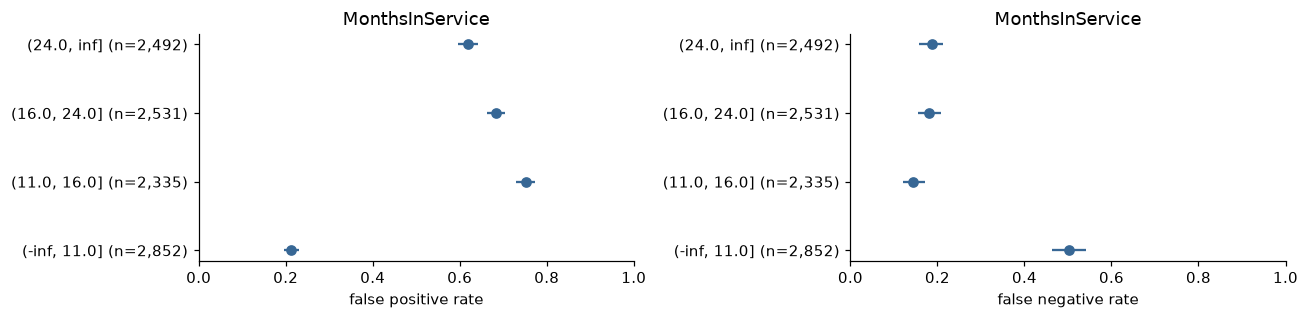

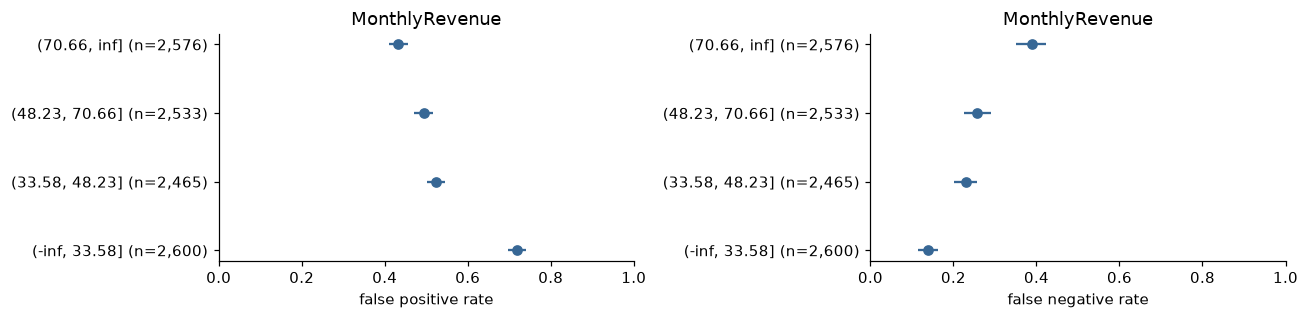

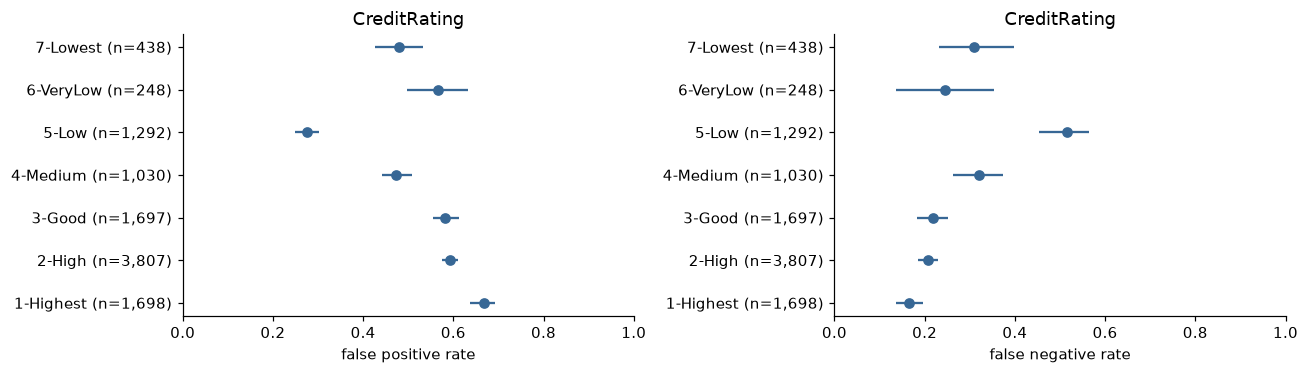

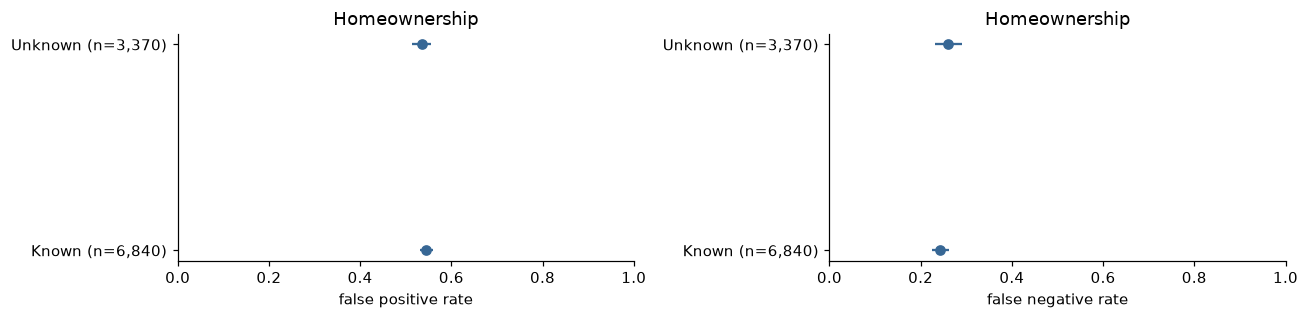

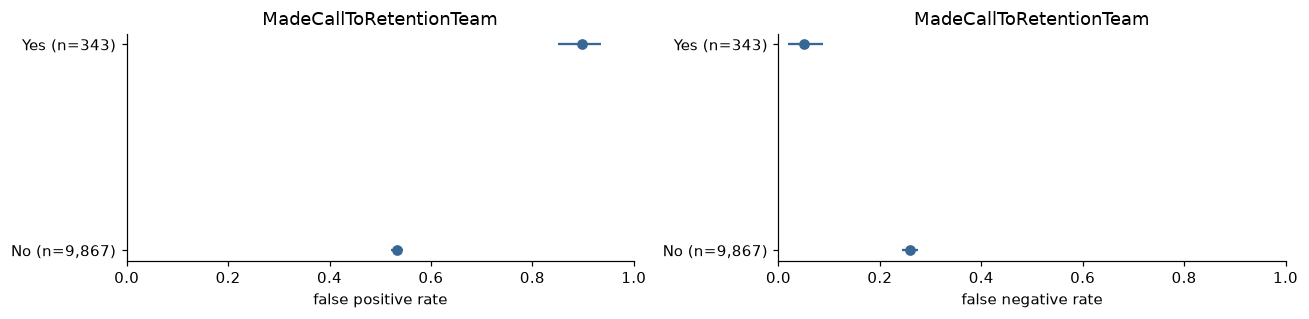

In [13]:
subgroups = {}
for name in ["MonthsInService", "MonthlyRevenue"]:
    edges = np.unique(X_train[name].dropna().quantile([0,.25,.5,.75,1]).to_numpy())
    edges[0], edges[-1] = -np.inf, np.inf
    subgroups[name] = pd.cut(X_test[name], bins=edges, include_lowest=True).astype("string").fillna("<missing>")
for name in ["CreditRating", "Homeownership", "MadeCallToRetentionTeam"]:
    train_values = X_train[name].astype("string").fillna("<missing>")
    counts = train_values.value_counts()
    common = counts[counts.ge(300)].index
    values = X_test[name].astype("string").fillna("<missing>")
    subgroups[name] = values.where(values.isin(common), "<other categories>")

def error_rates(labels, decisions):
    c = decision_counts(labels, decisions)
    tn, fp, fn, tp = [c[k] for k in ["true_negatives", "false_positives", "false_negatives", "true_positives"]]
    return {"false_positive_rate": fp/(tn+fp) if tn+fp else np.nan,
            "false_negative_rate": fn/(fn+tp) if fn+tp else np.nan,
            "precision": tp/(tp+fp) if tp+fp else np.nan}

subgroup_rows, subgroup_coverage = [], []
sub_rng = np.random.default_rng(2027)
for feature, groups in subgroups.items():
    suppressed_customers, suppressed_groups = 0, 0
    for group in sorted(groups.unique()):
        mask = groups.eq(group).to_numpy()
        labels, decisions = truth[mask], pred[mask]
        positive_n, negative_n = int(labels.sum()), int((labels==0).sum())
        if len(labels)<100 or min(positive_n, negative_n)<20:
            suppressed_customers += len(labels); suppressed_groups += 1; continue
        row = {"feature": feature, "group": str(group), "customers": len(labels),
               "actual_churners": positive_n, "actual_retained": negative_n,
               "flagged": int(decisions.sum()), **decision_counts(labels, decisions), **error_rates(labels, decisions)}
        samples = []
        for _ in range(500):
            idx = sub_rng.integers(0,len(labels),len(labels))
            samples.append(error_rates(labels[idx], decisions[idx]))
        samples = pd.DataFrame(samples)
        for metric in ["false_positive_rate", "false_negative_rate", "precision"]:
            row[metric+"_low"] = samples[metric].quantile(.025)
            row[metric+"_high"] = samples[metric].quantile(.975)
            row[metric+"_valid_resamples"] = int(samples[metric].notna().sum())
        subgroup_rows.append(row)
    subgroup_coverage.append({"feature": feature, "omitted_groups": suppressed_groups, "omitted_customers": suppressed_customers})
subgroup_errors = pd.DataFrame(subgroup_rows)
display(pd.DataFrame(subgroup_coverage).set_index("feature"))
display(subgroup_errors[["feature", "group", "customers", "actual_churners", "actual_retained", "flagged",
                         "false_positives", "false_negatives", "false_positive_rate", "false_negative_rate", "precision"]])
display(subgroup_errors[["feature", "group"]+[c for c in subgroup_errors if c.endswith(("_low", "_high", "_valid_resamples"))]])
for feature in subgroups:
    table = subgroup_errors.loc[subgroup_errors.feature.eq(feature)]
    fig, axes = plt.subplots(1,2,figsize=(12, max(3, .5*len(table))))
    for ax, metric in zip(axes, ["false_positive_rate", "false_negative_rate"]):
        ax.hlines(np.arange(len(table)), table[metric+"_low"], table[metric+"_high"], color="#376795")
        ax.plot(table[metric], np.arange(len(table)), "o", color="#376795")
        ax.set(yticks=np.arange(len(table)), yticklabels=[f"{g} (n={n:,})" for g,n in zip(table.group, table.customers)],
               xlim=(0,1), xlabel=metric.replace("_", " "), title=feature)
    plt.tight_layout(); plt.show()

### Subgroup findings

The shortest-tenure group, at most 11 months, contains 2,852 test customers. Its false-negative rate is 50.22% (bootstrap interval 46.23% to 54.16%), compared with 14.46% (12.15% to 17.04%) for the 11-to-16-month group. The corresponding false-positive rates are 21.21% and 75.18%. The single threshold therefore produces markedly different error balances across tenure groups.

Among customers with monthly revenue above the training upper quartile of 70.66, the false-negative rate is 38.87%; for those at or below 33.58, it is 13.78%. Credit-rating group `5-Low` has a false-negative rate of 51.50%, showing that the overall recall conceals uneven detection. These overlapping exploratory comparisons do not establish a reason to assign group-specific thresholds.

Prior retention-contact customers have a false-positive rate of 89.78% among 186 retained customers and a false-negative rate of 5.10% among 157 churners. That group contains only 343 test customers and is affected by the unresolved timing of retention variables. The 36 customers missing revenue are omitted from the revenue subgroup estimates because the group is below the reporting threshold; their outcomes remain included in the overall metrics.

### False positives and false negatives in context

The next summary compares training-selected numeric characteristics across test error types using group medians and missing-value fractions. It displays no individual error cases. All four confusion-matrix groups are kept separate so that missed churners can be compared with correctly identified churners, and false alerts with correctly retained customers.

These summaries do not isolate a causal explanation for an error. Differences can arise from score distributions, group prevalence, correlated predictors, and the frozen threshold. A follow-up investigation should use development data to propose changes and evaluate them on fresh customers.

In [14]:
error_labels = np.select([(truth==1)&(pred==0), (truth==0)&(pred==1), (truth==1)&(pred==1)],
                         ["missed churner", "false retention alert", "identified churner"], default="correct retention")
error_features = X_test[["MonthsInService", "MonthlyRevenue", "MonthlyMinutes", "CurrentEquipmentDays", "CustomerCareCalls", "RetentionCalls"]].copy()
error_features["error_type"] = error_labels
display(error_features.groupby("error_type").size().rename("customers").to_frame())
display(error_features.groupby("error_type").median())
display(error_features.drop(columns="error_type").isna().groupby(error_features.error_type).mean())

summary = {"dataset_sha256": dataset_sha, "split_sizes": results["split_sizes"],
           "selected_model": results["selected_model"], "threshold": threshold,
           "test": results["test"], "bootstrap_valid": len(boot),
           "intervals": intervals.reset_index(names="metric").to_dict(orient="records"),
           "paired_intervals": paired_intervals.reset_index(names="metric").to_dict(orient="records"),
           "calibration": calibration_summary.reset_index().to_dict(orient="records"),
           "numeric_relationships": numeric_relations.reset_index().to_dict(orient="records"),
           "correlation_pairs": [{"first": a, "second": b, "correlation": float(v)} for (a,b),v in pairs.loc[pairs.abs().sort_values(ascending=False).index].head(5).items()],
           "subgroups": subgroup_errors.to_dict(orient="records"), "workload": workload.to_dict()}
(WORK / "analysis_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("Aggregate analysis summary saved locally; individual predictions are not embedded in this notebook.")

,customers
error_type,
correct retention,3329
false retention alert,3939
identified churner,2211
missed churner,731


,MonthsInService,MonthlyRevenue,MonthlyMinutes,CurrentEquipmentDays,CustomerCareCalls,RetentionCalls
error_type,,,,,,
correct retention,11.0,53.740,518.0,209.0,0.7,0.0
false retention alert,19.0,42.075,288.5,445.0,0.0,0.0
identified churner,17.0,42.930,270.0,421.0,0.0,0.0
missed churner,12.0,56.250,543.0,212.0,1.0,0.0


,MonthsInService,MonthlyRevenue,MonthlyMinutes,CurrentEquipmentDays,CustomerCareCalls,RetentionCalls
error_type,,,,,,
correct retention,0.0,0.000601,0.000601,0.0,0.0,0.0
false retention alert,0.0,0.004824,0.004824,0.0,0.0,0.0
identified churner,0.0,0.006784,0.006784,0.0,0.0,0.0
missed churner,0.0,0.000000,0.000000,0.0,0.0,0.0


Aggregate analysis summary saved locally; individual predictions are not embedded in this notebook.


### Error-profile findings

Missed churners have median monthly minutes of 543 and median equipment age of 212 days, compared with 270 minutes and 421 days among identified churners. False alerts have median monthly minutes of 288.5 and equipment age of 445 days, compared with 518 minutes and 209 days among correctly retained customers.

These contrasts suggest that the frozen decision rule favors the older-equipment, lower-usage profile and can miss churners outside it. They describe the observed errors without identifying a causal mechanism or proving which inputs drive each prediction. A development-set feature-importance or ablation study would be needed to test that explanation.

## 9. Conclusions and limits

The random forest improves historical churn ranking over a constant prevalence score: test average precision is 0.425797 and ROC-AUC is 0.656335. Bootstrap intervals quantify uncertainty for the fixed model on this cohort. They do not include training variation or establish generalization to future subscribers.

The threshold of 0.44 flags 6,150 of 10,210 test customers (60.24%). It identifies 2,211 of 2,942 churners, but 3,939 alerts (64.05%) go to customers who stayed. That is about 2.78 contacts per historical churner found, with no evidence about how many departures contact would prevent. Subgroup diagnostics show that this workload and the missed-churner rate vary substantially across tenure, revenue, and credit-rating groups.

The forest overpredicts churn frequency in every displayed calibration bin and has worse Brier score than the constant prevalence baseline. Its ranking advantage should therefore be separated from claims about reliable individual probabilities, campaign profitability, or equitable error rates.

### Temporal and external validity

Temporal validation was not performed. The random split mixes customers from the same historical dataset and provides no estimate of future drift. A temporal study needs reliable observation dates, a defined prediction point, a fixed churn horizon, and features frozen before that point. None is invented here.

External validation was not performed. Another operator, region, tariff structure, or period may have different prevalence and predictor relationships. An external cohort would need compatible feature definitions, a documented outcome, lawful access, and evaluation without tuning to its labels. Bootstrap intervals cannot substitute for such a cohort.

### Remaining research and publication requirements

Feature timing, causal retention benefit, and fairness and privacy assessments remain incomplete. Earlier exposure to the test cohort limits claims about independent confirmation, even though this execution uses training-only EDA and validation-only selection. New modeling or calibration choices motivated by these diagnostics require fresh evaluation data.

The release contains original analysis, aggregate charts and tables, metrics, and confidence intervals. All saved outputs and 24 figures were reviewed for customer-level material. Raw records, individual predictions, and trained models remain local. The exact source CSV's rights remain unresolved: the published CC BY-SA 4.0 attribution for a separate Kaggle distribution does not establish a license for this mirror. [The provenance document](../docs/DATA.md) records the evidence and the scope of the publication audit. No permission to redistribute the CSV is asserted.

### Engineering implementation

The repository separately maintains reusable training code, automated tests, and model artifacts.